# 基于二叉树的并行股票交易评估（答案）

二叉树是一种树形数据结构，每个结点至多有左、右两个孩子。本实验以“股票交易评估”为背景，使用二叉树组织股票交易记录，在昇腾神经网络处理器（Neural Processing Unit，NPU）上通过 **平衡树方法** 并行计算成交量与成交额的前缀和，并通过成交量加权平均价格（Volume Weighted Average Price，VWAP）完成交易评估。

本实验学习大纲如下：

1. 环境准备：创建实验目录，检查数据文件并加载 CANN 环境；
2. 任务分析：分析股票交易评估问题，了解数据集、结点结构和实验参数，理解平衡树方法与并行分工；
3. 算法讲解：理解平衡树方法的正向遍历与反向遍历，结合示例掌握树的顺序存储、数据分块与多核并行计算过程；
4. 代码构建与运行：完成二叉树定义与构建、CPU 正向遍历与反向遍历、NPU 核函数、Host 调用及 CMake 构建；
5. 性能对比分析：使用默认交易编号分别运行 CPU 与 NPU 版本，通过结果表和标准条形图比较执行结果与性能；
6. 实验总结：归纳二叉树的数据组织方式与并行前缀和的实现过程。

**注：** 本实验使用 Python Notebook 组织讲解和代码生成，主要算法使用 C++ 编写。NPU 部分使用昇腾计算架构（Compute Architecture for Neural Networks，CANN）提供的 Ascend C 开发工具。


---
## 1. 环境准备

本实验项目名称为 `stock_trading_evaluation_tree`。首先创建实验所需目录，并加载 Ascend CANN 环境变量。

目录划分如下：

- `trades.txt`：股票交易记录数据集文件；
- `Source/stock_trading_evaluation_tree/include`：股票记录、二叉树及公共接口；
- `Source/stock_trading_evaluation_tree/src`：数据读取、CPU 树算法和测试程序；
- `Source/stock_trading_evaluation_tree/ascend`：Ascend C 核函数、Host 设备管理与调用程序；
- `Source/stock_trading_evaluation_tree/scripts`：构建与运行脚本；
- `Source/stock_trading_evaluation_tree/results`：正确性检查、前缀结果和计时结果。

实验环境为 Ascend 910B4、CANN 9.0.0。未检测到 CANN 时，可先运行 CPU 部分。


In [ ]:
# 准备工程目录并检查同目录的数据文件，不执行 NPU 计算。
from pathlib import Path
import os
import platform
import shlex
import shutil
import subprocess

NOTEBOOK_DIR = Path.cwd().resolve()
DATA_FILE = NOTEBOOK_DIR / 'trades.txt'
WORK_DIR = NOTEBOOK_DIR / 'Source' / 'stock_trading_evaluation_tree'
for name in ['include', 'src', 'ascend', 'scripts', 'results']:
    (WORK_DIR / name).mkdir(parents=True, exist_ok=True)
if not DATA_FILE.is_file():
    raise FileNotFoundError('请将 trades.txt 放在本 Notebook 所在目录，并从该目录启动 Notebook。')

# CANN 根目录或架构子目录中应包含运行时头文件；ASC 编译条件由构建脚本检查。
# 检查候选安装目录中是否存在 CANN Runtime 头文件。
def has_cann_runtime(path):
    return any((path / name).is_file() for name in
               ['include/acl/acl.h', 'runtime/include/acl/acl.h'])

candidates = []
for name in ['ASCEND_INSTALL_PATH', 'ASCEND_CANN_PACKAGE_PATH', 'ASCEND_TOOLKIT_HOME', 'ASCEND_HOME_PATH']:
    if os.environ.get(name):
        candidates.append(Path(os.environ[name]))
candidates += [Path('/usr/local/Ascend/cann'), Path('/usr/local/Ascend/cann/latest'),
               Path('/usr/local/Ascend/ascend-toolkit/latest')]
candidates += sorted(Path('/usr/local/Ascend/ascend-toolkit').glob('*/' + platform.machine() + '-linux'), reverse=True)
candidates += sorted(Path('/opt/conda/Ascend').glob('cann-*/' + platform.machine() + '-linux'), reverse=True)
CANN_PATH = next((p.resolve() for p in candidates if has_cann_runtime(p)), None)
if CANN_PATH is not None:
    env_file = next((p for p in [CANN_PATH / 'set_env.sh', CANN_PATH.parent / 'set_env.sh'] if p.is_file()), None)
    if env_file:
        cmd = 'source ' + shlex.quote(str(env_file)) + ' >/dev/null && env -0'
        loaded = subprocess.check_output(['bash', '-c', cmd])
        for item in loaded.split(b'\0'):
            if b'=' in item:
                key, value = item.split(b'=', 1)
                os.environ[key.decode()] = value.decode()
    os.environ['ASCEND_INSTALL_PATH'] = str(CANN_PATH)

HAS_ASCEND = platform.system() == 'Linux' and CANN_PATH is not None and shutil.which('npu-smi') is not None
print('数据文件：', DATA_FILE)
print('实验目录：', WORK_DIR)
print('CANN 路径：', CANN_PATH if CANN_PATH else '未检测到')
print('NPU 环境初检：', '已检测到 CANN 与 npu-smi；构建时继续检查 ASC 工具链和设备' if HAS_ASCEND else '未具备；后续仅运行 CPU 检查')


---
## 2. 任务分析

### 2.1 股票交易评估问题

股票在一个交易日内会以不同价格、不同成交量多次成交。交易者可以将自身成交价与 VWAP 比较，评价成交价相对市场平均水平的优劣。从卖方视角看，在同一统计范围内，成交价高于 VWAP 表示卖出价格优于该基准。

成交量加权平均价格（Volume Weighted Average Price，VWAP）以成交量作为权重，其计算公式为：

$$
\mathrm{VWAP}=\frac{\displaystyle\sum_{i=1}^{n}T_i}{\displaystyle\sum_{i=1}^{n}V_i}
$$

其中，$n$ 为统计范围内的成交记录数，$T_i$ 为第 $i$ 笔成交的成交额（美元），$V_i$ 为第 $i$ 笔成交的成交量（股），因此 VWAP 的单位为美元每股。

本实验输入一笔成交的交易编号 `trade_id`，将其成交价与 **同一股票、同一交易日，从首条记录累计至该笔成交完成** 的 VWAP 比较：

- 成交价大于 VWAP，输出“投资成功”；
- 成交价小于或等于 VWAP，输出“投资失败”；
- 交易编号不存在，输出“查找失败”。

**注：** 这里的评价标签只表示成交价格相对 VWAP 的优劣。数据未包含投资者身份和交易方向，本任务中假定数据集中的交易均来自卖方。


### 2.2 结构体定义

#### 2.2.1 股票交易记录

`trades.txt` 首行为表头，字段之间以空白分隔。每条记录包含以下信息：

| 字段 | 含义 |数据类型 | 说明 |
| --- | --- | --- | --- |
| `trade_id` | 交易编号 | `int` | 唯一标识成交记录 |
| `stockcode` | 股票代码 | `string` | 如 AAPL、MSFT |
| `date` | 交易日期 | `string` | YYYYMMDD 格式 |
| `time` | 交易时间 | `long long` | 美东时间当天零点起累计的纳秒数 |
| `volume_t` | 成交量 | `int` | 单位为股 |
| `price` | 成交价 | `int` | 美元每股价格放大 10000 倍后的整数 |
| `turnover_t` | 成交额 | `long long` | 美元成交额放大 10000 倍后的整数 |

根据上述字段，股票交易记录的结构体定义如下：

```cpp
typedef struct trades {
    int trade_id;          // 交易编号
    string stockcode;      // 股票代码
    string date;           // 交易日期
    long long time;        // 交易时间
    int volume_t;          // 成交量
    int price;             // 成交价
    long long turnover_t;  // 成交额
} trades;                 // 股票交易记录
```

#### 2.2.2 二叉树

回顾《数据结构（C 语言版）》中二叉树的顺序存储结构：

```cpp
//-----二叉树的顺序存储表示-----
#define MAXTSIZE 100                 // 二叉树的最大结点数
typedef TElemType SqBiTree[MAXTSIZE]; // 0号单元存储根结点
SqBiTree bt;
```

其中，`TElemType` 表示结点的数据类型，`SqBiTree` 是二叉树的顺序存储类型，`bt` 是该类型的一个数组。树中结点按层从上到下、同层从左到右存入数组，根结点位于下标 0，双亲结点与孩子结点的联系由数组下标表示。

采用顺序存储的二叉树的数组下标具有规律，若根结点放在数组下标 0 处，则对于数组下标 $i$：

- 左孩子下标为 $2i+1$；
- 右孩子下标为 $2i+2$；
- 当 $i>0$ 时，双亲下标为 $\lfloor(i-1)/2\rfloor$。

在高度 $h$ 上，当前层共有 $n/2^h$ 个结点，该层第 $j$ 个结点对应的实际数组下标为：$i=\frac{n}{2^h}+j-2.$


### 2.3 实验参数

本实验的参数主要包括：

- `TRADE_ID`：待评价的交易编号；
- `CORE_NUM`：NPU上启动计算核个数；
- `WARMUP`、`REPEAT`：预热与正式计时次数；
- `SOC_VERSION`：实际设备对应的编译型号，留空时由运行脚本检测。


In [ ]:
# 运行参数：
TRADE_ID = 265877384      # 本任务的默认输入值
CORE_NUM = 32
WARMUP = 2
REPEAT = 10
SOC_VERSION = 'ascend910b4'

## 3. 算法讲解


本算法完整流程为：

> 定义数据结构 → 读取数据并确定树的规模 → 数据分块与任务分配 → 树的构建 → 正向遍历 → 反向遍历 → 计算 VWAP 并评估。

具体关键步骤：

1. 定义数据结构：
基于给定的股票交易记录结构体 trades，定义二叉树的顺序存储类型 SqBiTree，以及数组 B、C。其中，B 保存正向遍历得到的子树和，C 保存反向遍历得到的前缀结果。

2. 读取数据，确定树的规模：
根据输入的交易编号，找出同一股票当日的全部成交记录，并按成交顺序排列。根据平衡树方法，需要构建一棵满二叉树，因此需将叶子结点数补齐为不小于记录数的最小的 2 的幂。
例如，假设输入 65 个数，则应补零至 128，对应 128 个叶子结点、255 个结点。

3. 数据分块与任务分配：
划分叶子结点位置对应的输入范围，再将计算任务分配给各核。
在这个例子中，假设每个数据块大小为8，则该 128 个叶子结点可划分为 16 个数据块。其中 9 块包含真实数据，其余 7 块全部为零。

4. 树的构建：
将真实成交记录依次存入 B 的叶子结点位置，其余叶子结点和内部结点的成交量、成交额均初始化为零。
在这个例子中，B 的有效下标为 0～254，叶子结点存放在 B[127]～B[254]。双亲结点在正向遍历中由孩子结点确定。

5. 正向遍历：计算各棵子树的和。
从叶子结点的上一层开始，各核并行计算当前层的结点，将两个孩子的成交量、成交额分别相加，写入双亲结点。当前层全部计算完成后，再计算上一层，直到根结点得到整日总和。

6. 反向遍历：计算所有位置的前缀和。
从根层开始，按照教材的三种情况计算 C。各核并行处理当前层结点，完成后再处理下一层，直到叶子结点层。最终，每个叶子结点的 C 值就是截至该笔成交的累计成交量和累计成交额。

7. 计算 VWAP，并进行交易评估：
读取目标成交对应的前缀结果，计算累计 VWAP，与目标成交价比较，输出“投资成功”或“投资失败”。

### 3.1 平衡树方法

**前缀和：** 是从序列的第一个数开始，累加到当前位置得到的和。

例如，对于序列 `9、10、11、12、13、14、15、16`，各位置的前缀和为 `9、19、30、42、55、69、84、100`。

本实验中，基于 **树形数据结构** ，通过 **平衡树方法** 实现前缀和计算。

#### 3.1.1 数据准备

令 $A(i)=x_i\ (1\leq i\leq n)$；令 $B(h,j)$ 和 $C(h,j)$ 是辅助数组。其中，数组 B 用于记录正向遍历时树中各结点的信息，数组 C 用于记录反向遍历时树中各结点的信息。

算法中用到的各符号的含义如下：

| 符号 | 含义与取值范围 |
| --- | --- |
| $n$ | 叶子结点数，为便于说明，先假设 $n=2^k$ |
| $k$ | 树的最大高度，$k=\log_2 n$ |
| $h$ | 当前层的高度，$0\leq h\leq k$；叶子结点在第 0 层，根结点在第 $k$ 层 |
| $j$ | 当前层从左到右的编号，$1\leq j\leq n/2^h$，每层均从 1 开始编号 |
| $A(i)$ | 第 $i$ 个输入，$1\leq i\leq n$ |
| $B(h,j)$ | 以该结点为根的子树中，所有叶子结点数值的和 |
| $C(h,j)$ | 从第一个输入开始，累计到该结点所覆盖范围最右端的和 |

例如，$B(h,j)$ 统计第 $(j-1)2^h+1$ 至第 $j2^h$ 个输入；$C(h,j)$ 统计第 1 至第 $j2^h$ 个输入。因此，B 记录的是一段子树范围的和，C 记录的是从序列起点开始的累计值。

**注意：** $B(h,j)$ 是教材描述结点位置的数学记号，`B[...]` 是 C++ 的实际数组访问；只进行下标换算，不改变计算规则。C 的下标换算方法相同。以下示例先用一组整数说明算法，实际任务对成交量和成交额分别采用相同的计算规则。

#### 3.1.2 正向遍历：计算子树和

先将输入写入叶子结点：

$$B(0,j)=A(j),\qquad 1\leq j\leq n.$$

随后从叶子结点的上一层开始，逐层计算至根结点：

$$\boxed{B(h,j)=B(h-1,2j-1)+B(h-1,2j)}$$

其中 $h=1,2,\ldots,k$，$j=1,2,\ldots,n/2^h$。也就是：**双亲结点的子树和等于左孩子与右孩子的子树和之和。**

下图 3-1 展示了正向遍历过程，其中的箭头表示数据从输入进入叶子结点，再由孩子结点逐层计算到双亲结点。

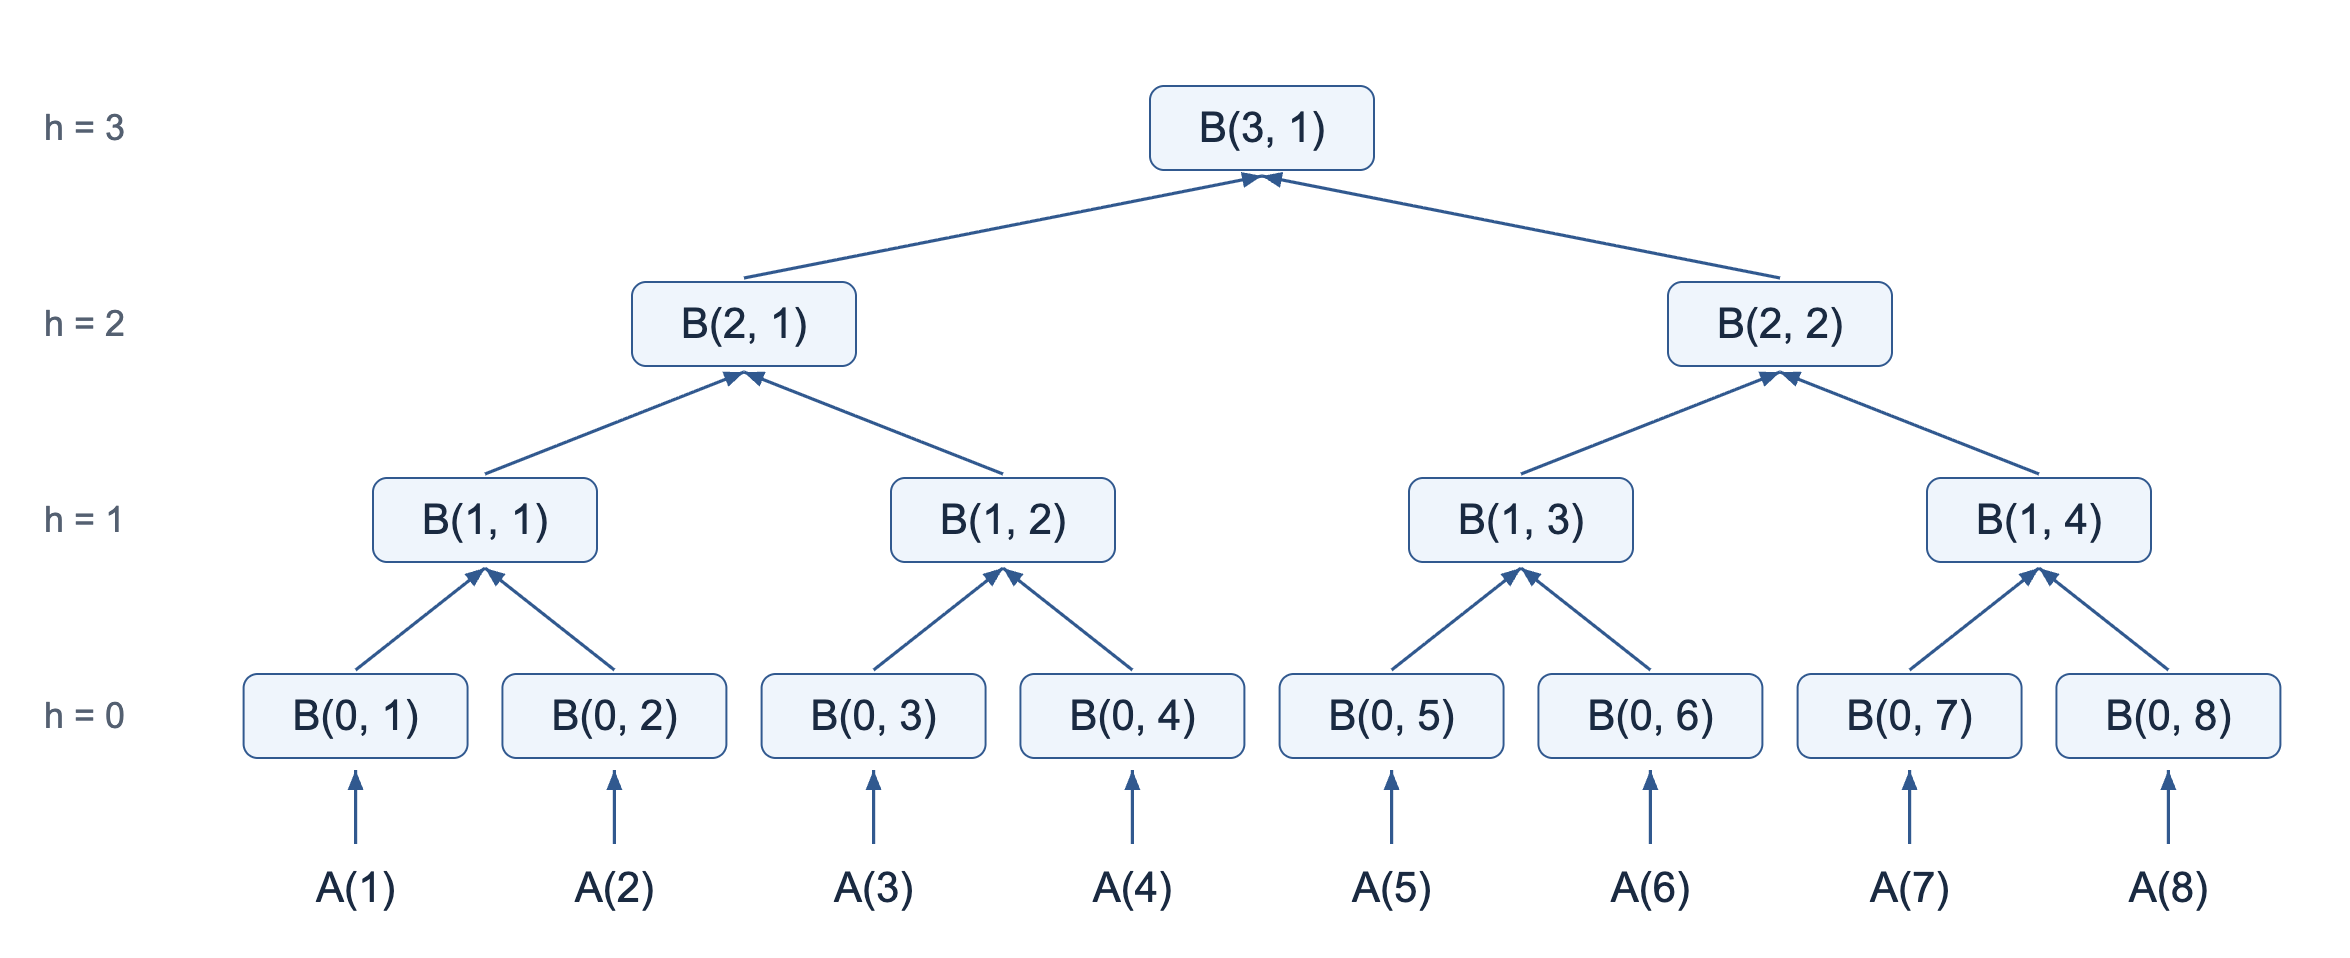

下面通过一个小例子，说明两次遍历如何得到前缀和。设输入为：

$$A=(9,10,11,12,13,14,15,16).$$

此时 $n=8$、$k=3$，共有 15 个结点。8 个叶子结点依次放在 `B[7]` 至 `B[14]`。先计算第 1 层，例如：

$$B(1,1)=9+10=19,\qquad B(1,3)=13+14=27.$$

继续将相邻两个孩子的结果相加，直到根结点。下图每个结点的上方数字表示数值，下方的 `B[...]` 表示实际数组位置；左侧标出该层的高度 $h$。

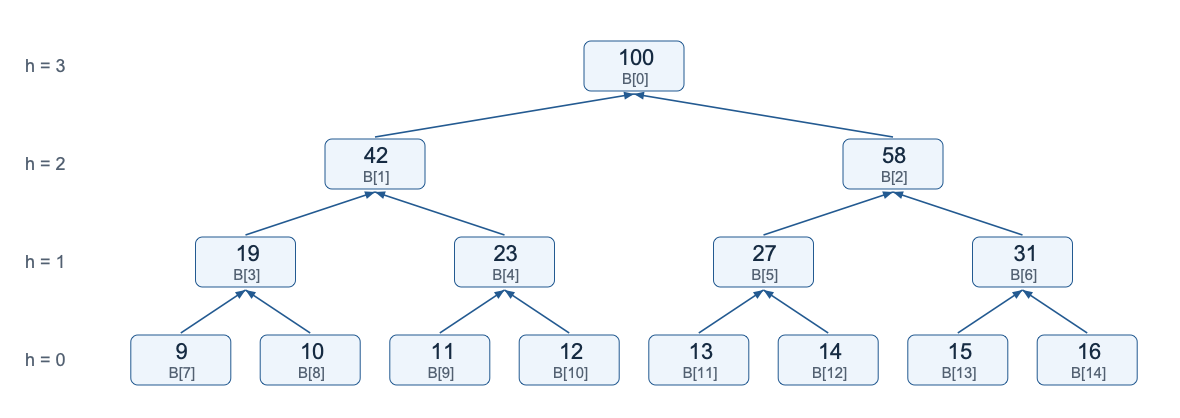

对照上图 3-2，可以看出：$B(1,3)=27$ 表示 13、14 的和，$B(2,2)=58$ 表示 13、14、15、16 的和，而 $B(3,1)=100$ 表示全部叶子结点的总和。

**注意：** 正向遍历得到了各棵子树的和，但尚未得到所有位置的前缀和。例如，第五个叶子结点中的值仍为 13，而前五个输入的和应为 55。

#### 3.1.3 反向遍历：计算前缀和

反向遍历从根结点逐层计算到叶子结点。对于每一层，按结点在该层的编号 $j$ 分三种情况计算：

$$
\boxed{
C(h,j)=
\begin{cases}
B(h,1), & j=1,\\[2mm]
C(h+1,j/2), & j\text{ 为偶数},\\[2mm]
C(h+1,(j-1)/2)+B(h,j), & j>1\text{ 且为奇数}.
\end{cases}}
$$

其中 $h=k,k-1,\ldots,0$，$j=1,2,\ldots,n/2^h$。根层只有 $j=1$，因此从 $C(k,1)=B(k,1)$ 开始。计算下一层时，需要用到的上一层 C 值已经得到。

**（1）当前层的第一个结点：$j=1$。**

它前面没有其他输入范围，因此自己的子树和就是当前的累计值：

$$C(h,1)=B(h,1).$$

例如，$C(2,1)=B(2,1)=42$，表示前四个输入的和。

**（2）当前结点是右孩子：$j$ 为偶数。**

右孩子与双亲结点所覆盖范围的右端相同，二者从序列起点累计到的位置也相同，因此直接取双亲结点的累计值：

$$C(h,j)=C(h+1,j/2).$$

例如，$C(1,4)=C(2,2)=100$，都表示从第一个输入累计到第八个输入的和。

**（3）当前结点是其余左孩子：$j>1$ 且为奇数。——本算法的重难点。**

这时，要先取得当前子树前面所有输入的累计值，再加上当前子树的和。前面的累计范围由上一层中、当前双亲结点左侧的相邻结点给出，其编号为 $(j-1)/2$。注意，这里取的不是当前结点自己的双亲结点。

$$C(h,j)=C(h+1,(j-1)/2)+B(h,j).$$

例如，$C(1,3)$ 表示前六个输入的和。前四个输入的和为 $C(2,1)=42$，当前子树包含 13、14，其和为 $B(1,3)=27$，因此：

$$C(1,3)=C(2,1)+B(1,3)=42+27=69.$$

下图 3-3 展示了反向遍历的计算过程。每次先计算当前层，再计算它下面的一层。

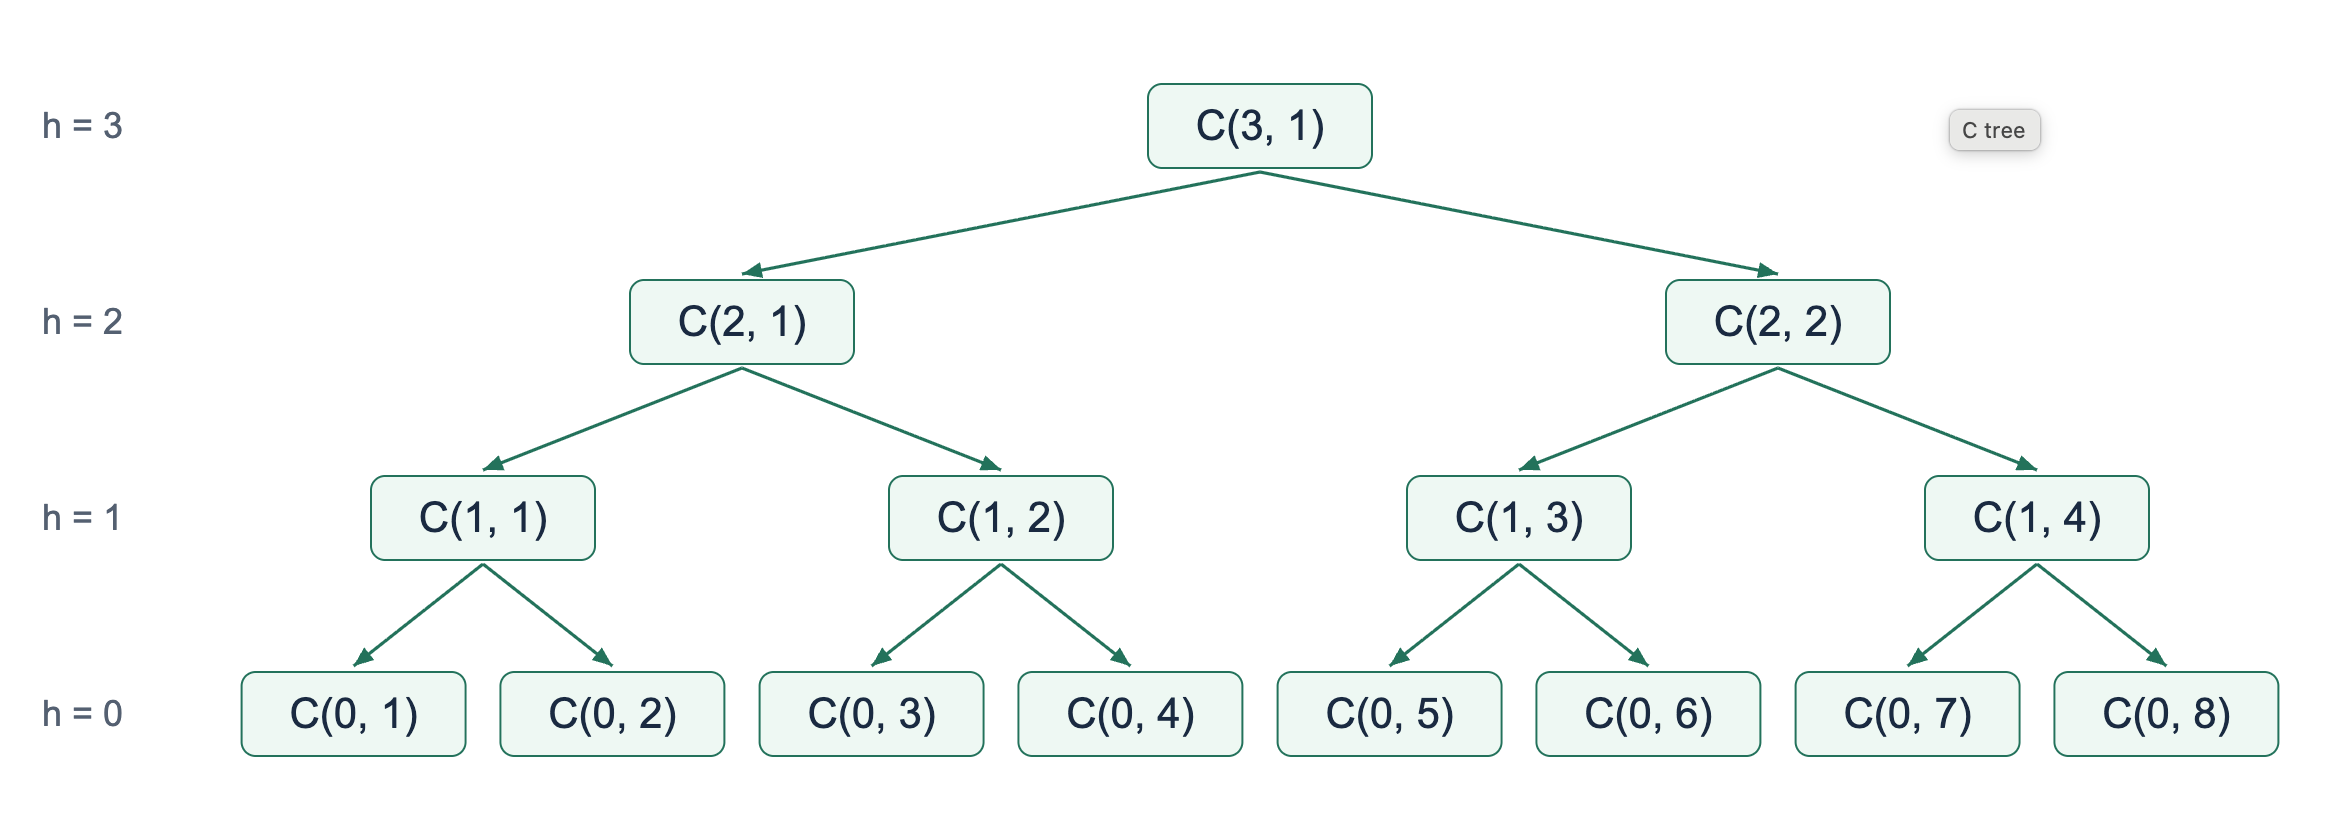

仍使用上述示例，按照三种情况逐层计算，得到下面的 C。每个结点同样标出数值、实际数组下标以及所在层的高度，如下图 3-4 所示为八个数完成反向遍历后的数组 C 。

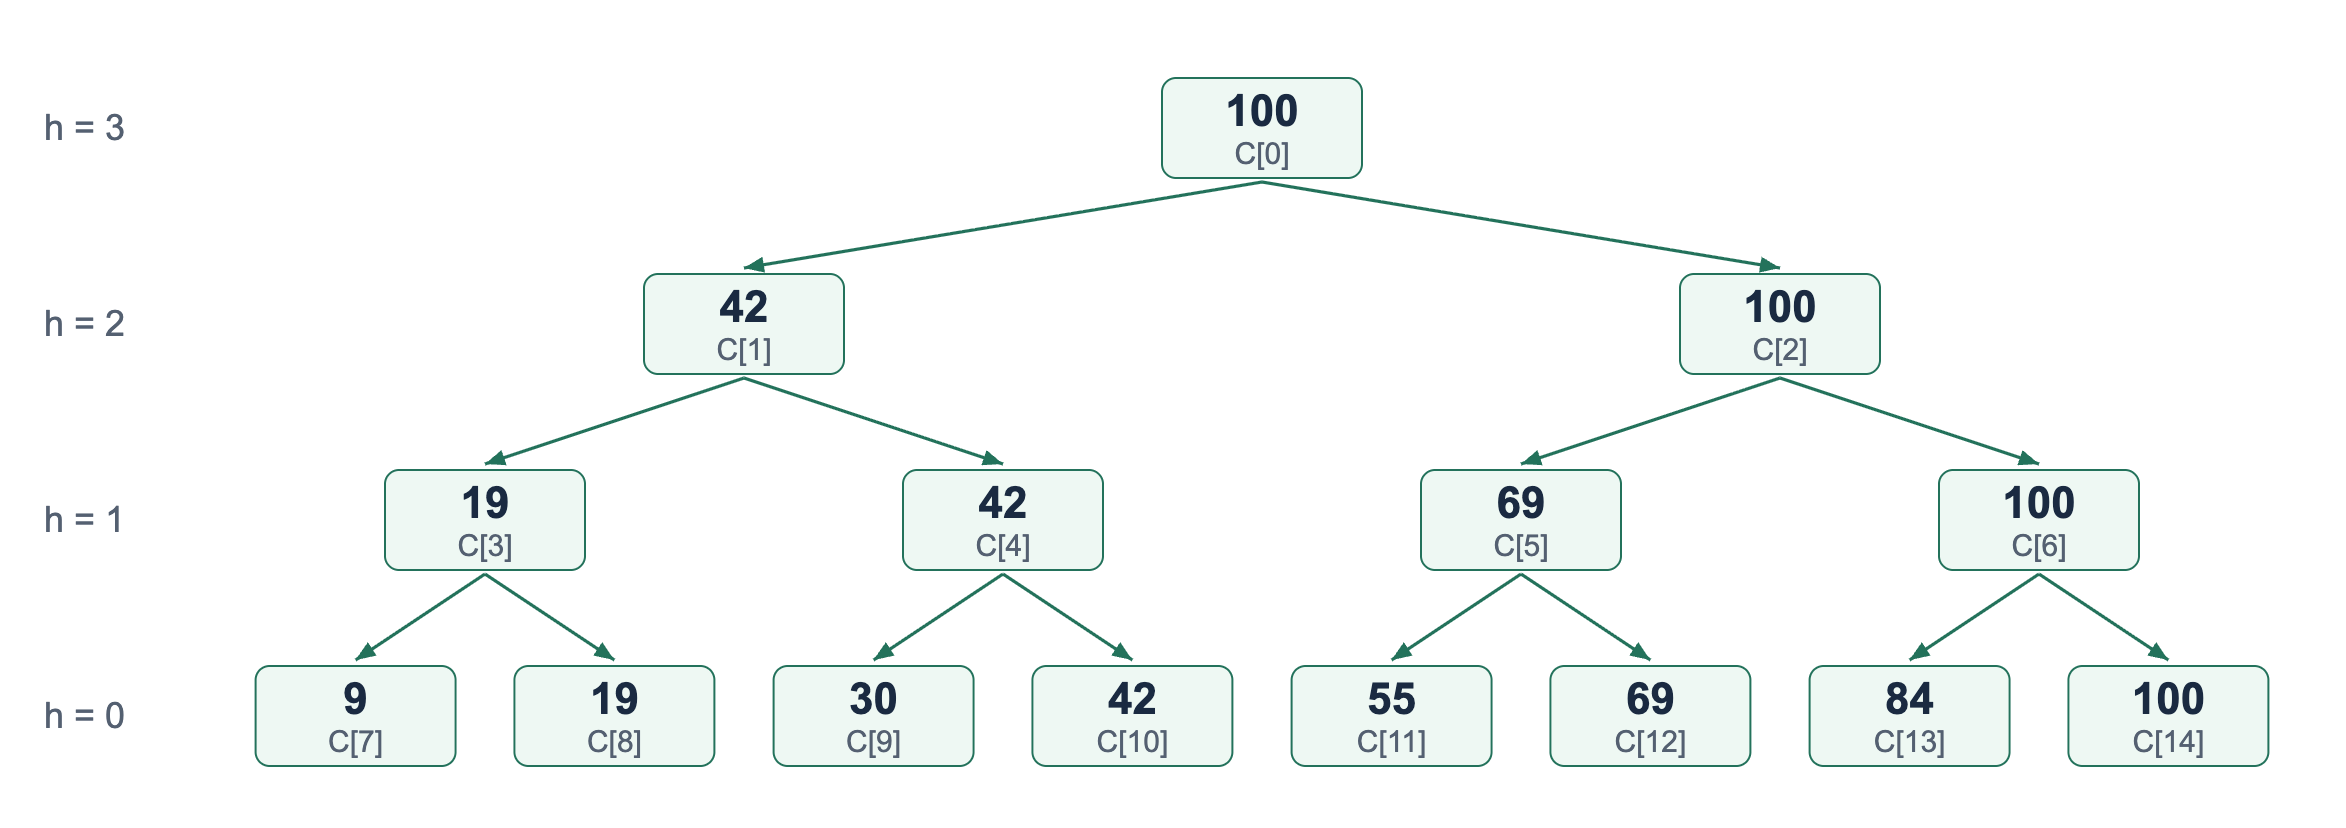

例如，第五个叶子结点满足 $h=0$、$j=5$，因此：

$$C(0,5)=C(1,2)+B(0,5)=42+13=55.$$

叶子结点对应单个输入，所以最终有：

$$\boxed{C(0,j)=A(1)+A(2)+\cdots+A(j)}.$$

从左到右读取 C 的叶子结点，得到 `9、19、30、42、55、69、84、100`。本实验分别对成交量和成交额计算前缀和，再读取目标成交对应位置的两项累计值。

### 3.2 并行实现

前面已经说明每个结点怎样计算。并行实现还需要确定：输入怎样分块，各核分别计算哪些结点，以及不同层之间何时可以继续计算。

#### 3.2.1 确定树的规模与补零

假设输入个数为 $n=2^k$。实际成交记录数不一定满足这一条件，因此先将叶子结点数补齐为不小于有效记录数的最小的 2 的幂，补入位置的成交量、成交额均为零。整棵树共有 $2n-1$ 个结点，叶子结点存放在数组下标 $n-1$ 至 $2n-2$。

**重难点：65 个输入按 128 个叶子结点安排，不足的位置补零，所有叶子结点统一存放在数组 B 中。**即使每个数据块大小为 8，也应补零至 **128 个叶子结点，而不是 $65+7=72$ 个**。72 只保证记录数能被 8 整除，仍不满足本算法的 $n=2^k$ 条件。

补齐后共有 255 个结点，B 的有效下标为 `0～254`，叶子结点区为 `B[127]～B[254]`。按照每块 8 个叶子结点位置划分，共有 16 块：前 8 块各有 8 个真实输入，第 9 块有 1 个真实输入和 7 个零，其余 7 块全部为零。正向遍历计算双亲结点的数值，双亲与孩子的位置关系在数组下标确定时已经建立。

#### 3.2.2 数据分块与任务分配

下面以一个较小的例子说明并行分工。设输入为 **1 至 27，共 27 个数**，数据块大小为 **8**。先确定补齐后的叶子结点数为 32，再将叶子结点位置划分为四块，并将它们分别分配给核 0 至核 3。

前三个数据块各有 8 个真实输入，第四个数据块只有 25、26、27 三个真实输入，需要在末尾补 5 个零。因此，补零后共有 $27+5=32$ 个叶子结点。具体分块如下图 3-5 所示，这 32 个叶子结点依次存放在 `B[31]～B[62]`。每个数据块对应树底部一棵包含 8 个叶子结点的子树，相邻子树上方仍有双亲结点，继续连接到根结点。B 保存整棵树的子树和，C 保存相同树形下的前缀结果。其中，浅橙色位置为补入的零。

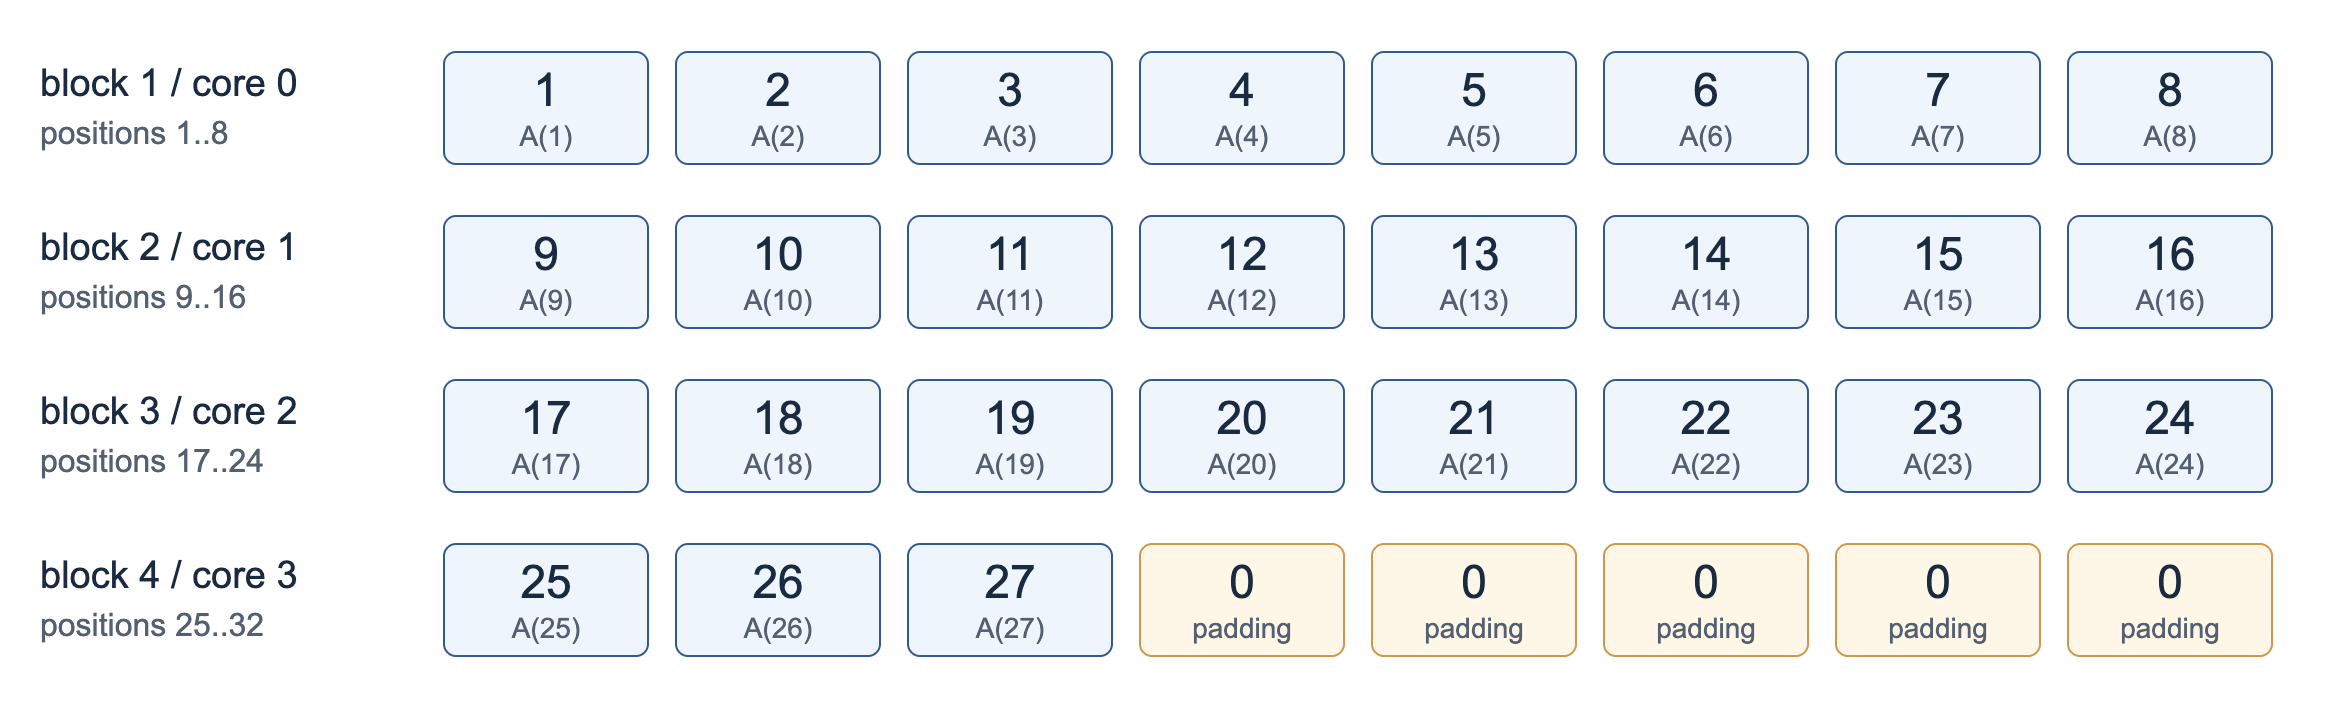

#### 3.2.3 各层计算任务与结果合并

**正向遍历中的分工：** 

核 0 至核 3 先并行计算各自数据块对应的子树，得到高度 $h=3$ 上的四个结果：

| 数据块 | 包含的真实输入 | 子树和 |
| --- | --- | --- |
| 第 1 块 | 1～8 | 36 |
| 第 2 块 | 9～16 | 100 |
| 第 3 块 | 17～24 | 164 |
| 第 4 块 | 25～27 | 78 |

这四个结果继续按照树中的双亲与孩子关系两两相加：核 0 计算 $36+100=136$，核 1 计算 $164+78=242$；当前层完成后，由核 0 计算根结点 $136+242=378$。下图 3-6　中数据块的求和结果继续合并至根结点，每个结点标出数值与实际数组下标。

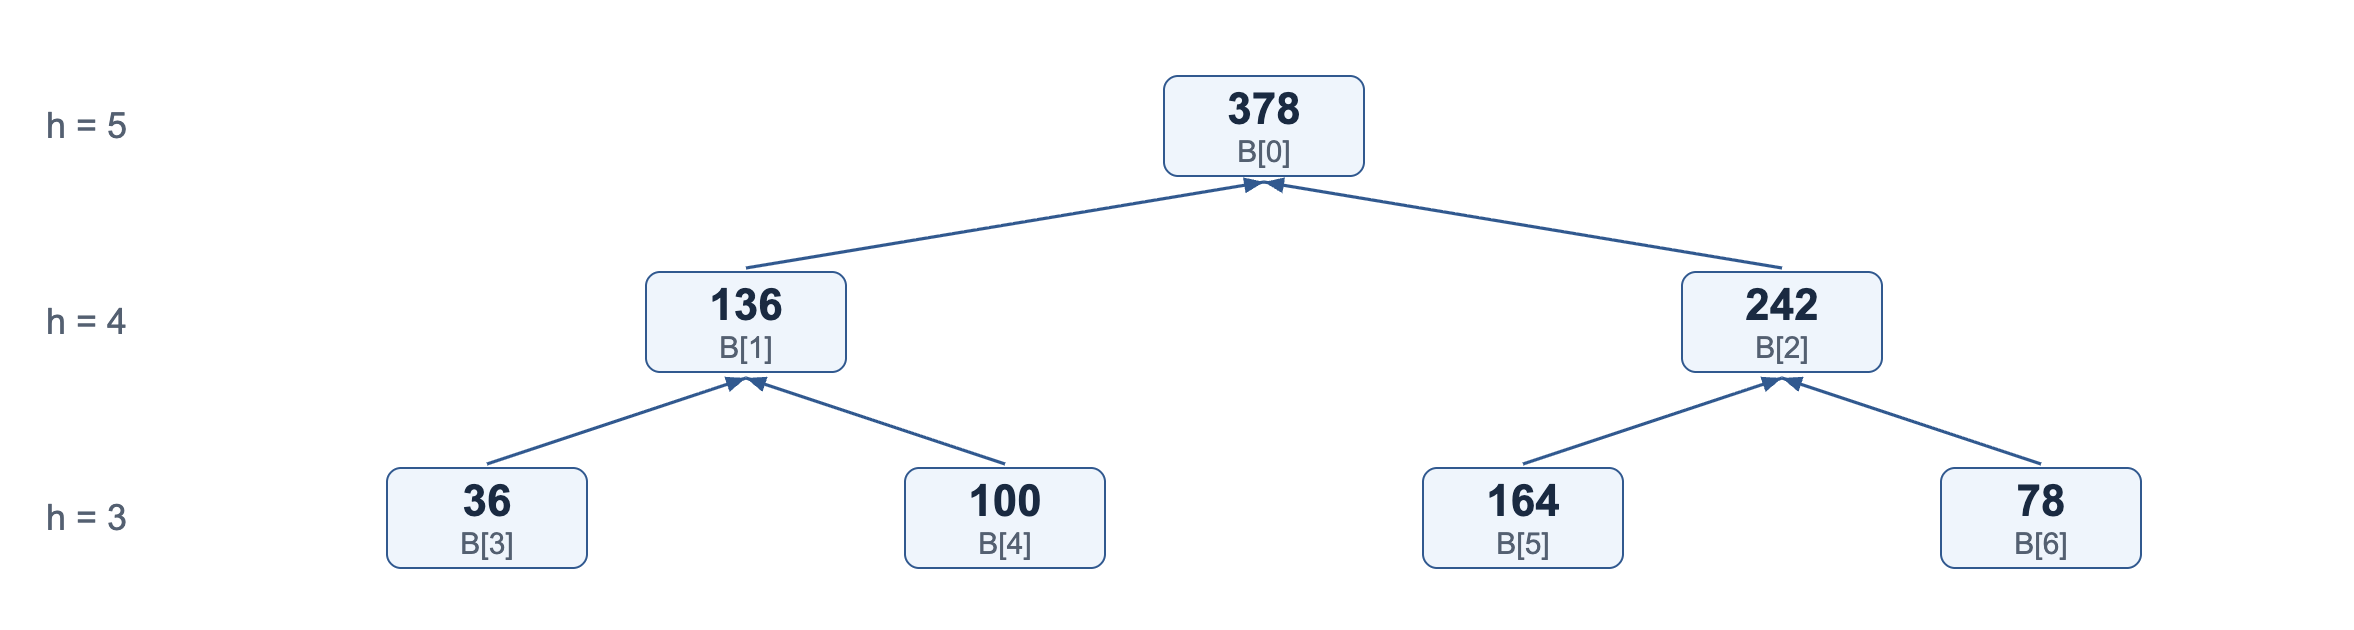

这里每个双亲结点始终只合并两个孩子的结果。一个计算核可以计算多个双亲结点，数据块大小为 8 不表示一次必须把 8 个子树和合成一个结果。

以上例为例，各层的任务分配如下。正向遍历按 $h=1,2,\ldots,5$ 执行；反向遍历按 $h=5,4,\ldots,0$ 执行。

| 高度 $h$ | 当前层结点数 | 当前层的任务分配 |
| --- | --- | --- |
| 5 | 1 | 核 0 计算 1 个结点，其余核没有当前层任务 |
| 4 | 2 | 核 0、核 1 各计算 1 个结点 |
| 3 | 4 | 四个核各计算 1 个结点 |
| 2 | 8 | 四个核各计算相邻的 2 个结点 |
| 1 | 16 | 四个核各计算相邻的 4 个结点 |
| 0 | 32 | 四个核各处理相邻的 8 个叶子结点位置 |

第 0 层在正向遍历前用于初始化输入，在反向遍历结束时得到最终前缀结果。靠近根结点时，当前层的结点变少，因此有任务的核也会减少。

**反向遍历中的分工：**

根结点的总和 378 只说明 27 个输入的总和，还不能代替各位置的前缀和。反向遍历仍按前面 C 的三种情况逐层计算，并按照上表分配各层结点。计算至 $h=3$ 时，四个数据块最右端的累计值分别为 `36、136、300、378`；继续计算到第 0 层，才能得到每个真实输入的前缀和。

例如，第 2 块的第一个数为 9，它前面已有第 1 块的累计值 36，因此该位置的前缀和应为 $36+9=45$。这里仍然使用教材的反向遍历公式逐层计算，结点编号 $j$ 按整层确定，不在每个数据块中重新从 1 开始。

最终四个数据块对应的真实输入前缀为：

| 数据块 | 最终前缀结果 |
| --- | --- |
| 第 1 块 | 1、3、6、10、15、21、28、36 |
| 第 2 块 | 45、55、66、78、91、105、120、136 |
| 第 3 块 | 153、171、190、210、231、253、276、300 |
| 第 4 块 | 325、351、378 |

最后 5 个补零位置也参与计算，其前缀值均为 378，但它们不对应真实成交记录，不参与交易评价。

#### 3.2.4 层间同步与实际核数

同一层中的不同结点可以并行计算；不同层之间存在先后依赖。**必须等当前层的全部计算核完成后，再计算依赖该层结果的下一层。**在 NPU 程序中，Host 负责按层组织核函数调用，并保证下一层开始前，所依赖的数据已经计算完成且可见。

本实验默认启动 **32 个计算核**。示例中的块长 8 用于说明分工；实际运行时，按照补齐后的叶子结点数 $n$ 和参与分工的核数 $p$ 分配输入范围。在教材假设的 $p\leq n$、$n$ 与 $p$ 均为 2 的幂时，每核最初负责 $n/p$ 个叶子结点位置。后续按每层的结点数重新确定各核任务；当前层结点数少于核数时，只有前面的部分计算核有任务。

完成两次遍历后，从 C 的叶子结点区读取目标成交的累计成交量和累计成交额，按统一单位计算 VWAP，再完成卖方视角的价格评价。

**注：** 本节算法详细内容可参考陈国良《并行算法的设计与分析》第 2 章。

---
## 4. 代码构建与运行

本节把第 3 部分的算法写成完整程序。先在 CPU 上用数组 B、C 完成正向遍历与反向遍历，再在 NPU 上按层分配计算任务。两条计算路径均对同一股票当日的全部记录计算前缀和，最后取目标成交对应的累计值进行评价。

#### 项目结构

**提示：** 点击 **文件名** 可跳转到对应文件的说明及代码单元格。

| 位置 | 文件 | 功能 |
| --- | --- | --- |
| `include/` | [`trades.hpp`](#tree-types-code) | 成交记录、树的顺序存储类型与前缀数值定义 |
|  | [`bi_tree.hpp`](#tree-interface) | 数组树构建与两次遍历接口 |
|  | [`trade_utils.hpp`](#tree-trade-interface) | 数据读取、交易评估与实验参数接口 |
|  | [`device_tree.hpp`](#tree-device-types) | 设备数值条目及存储布局 |
| `src/` | [`bi_tree.cpp`](#tree-cpu-code) | 全局 B、C 数组、树的构建与 CPU 两次遍历 |
|  | [`trade_utils.cpp`](#tree-trade-code) | 数据读取、参考检查与交易评价 |
|  | [`cpu_main.cpp`](#tree-cpu-main) | CPU 运行入口 |
|  | [`test_common.cpp`](#tree-common-test) | 数组树与前缀算法功能检查 |
| `ascend/` | [`stock_vwap_npu.asc`](#tree-asc) | 两个单层核函数、设备管理、逐层调用与结果读取 |
| `scripts/` | [`cann_environment.sh`](#tree-scripts) | 加载 CANN 环境并查找 ASC 工具链 |
|  | [`run.sh`](#tree-run-script) | 构建与运行 NPU 程序 |
| 项目根目录 | [`CMakeLists.txt`](#tree-cmake) | 项目编译配置 |

**注：** `results` 中的文件由运行过程生成。


### 4.0 实操任务

本实践围绕股票交易评估，依次完成二叉树的顺序存储定义、树的构建、数据分块、基于平衡树方法的并行前缀和计算及 VWAP 交易评估，理解数组下标如何表示树形关系，以及多个 NPU 计算核如何共同完成两次遍历。

完成后应能够：

1. 根据给定的成交记录结构体定义二叉树的顺序存储类型，理解 B、C 两个数组分别保存的内容；
2. 确定补齐后的叶子结点数，将成交记录按顺序存入叶子结点位置，理解真实记录数、叶子结点数和树的结点总数之间的区别；
3. 根据当前层结点数、实际启动核数及当前核编号划分数据块，保证每层结点被完整覆盖，且各核处理的范围互不重叠；
4. 在给出的 Ascend C 框架中完成正向遍历与反向遍历的数值更新，理解子树和如何转化为各位置的前缀和；
5. 从目标成交对应的前缀结果计算累计 VWAP，并根据卖方视角评价成交价格。

操作方式：

1. 先阅读任务说明；
2. 在带有 `TODO` 的代码单元中补全代码；
3. 完成补全并生成对应文件后，运行第四部分末尾的检查单元，检查该任务是否正确：通过时显示 `PASSED`，未通过时显示 `FAILED`；缺少文件或编译环境时显示 `SKIPPED`；
4. 测试通过后再进入下一项任务。

本实践共包含 5 个任务：

- **任务一：** 二叉树的定义——使用标准 C++ 定义二叉树及辅助数组；
- **任务二：** 二叉树的构建——确定叶子结点数并保存成交记录；
- **任务三：** 数据分块——为当前层的结点划分计算范围；
- **任务四：** 实现平衡树方法的正向遍历和反向遍历——在 NPU 上计算成交量与成交额的前缀和；
- **任务五：** VWAP 计算与交易评估——根据累计 VWAP 评价卖出成交价格

#### 4.0.1 任务一：二叉树的定义

根据已经给出的股票交易记录结构体 `trades`，定义二叉树的顺序存储类型 `SqBiTree`。类型定义规定数组元素类型和容量；变量定义则建立实际使用的数组。B 保存正向遍历得到的子树和，C 保存反向遍历得到的前缀结果，两者的根结点均位于下标 0。

请补全：

- `TODO 1A`：用 `typedef` 定义 `SqBiTree`，使它表示含有 `MAXTSIZE` 个 `trades` 元素的数组。`MAXTSIZE = 300000` 已经给出，表示一棵树的结点容量。（[4.1.1（1）成交记录与二叉树：`trades.hpp`](#tree-types-code)）
- `TODO 1B`：使用 `SqBiTree` 分别定义全局数组 B、C，使不同函数可以访问同一组树形数据。（[4.1.2（1）数组树的构建与两次遍历：`bi_tree.cpp`](#tree-cpu-code)）

**提示：** 头文件中给出的 `extern SqBiTree B;` 是声明，表示“程序中存在名为 B 的数组，具体定义在其他源文件中”。本实验在 `bi_tree.cpp` 中用 `SqBiTree B;` 定义数组并分配存储空间。C 的处理相同；`extern` 声明无需补全。

完成后分别运行两个[任务一检查](#tree-task1a-check)，检查存储类型及两个数组的定义。

#### 4.0.2 任务二：二叉树的构建

输入序列在代码中统一命名为 `A`。它使用 `vector<trades>` 暂存同一股票当日按成交顺序排列的记录，对应算法讲解中的输入 A；`A[i]` 是一条完整成交记录，其中 `A[i].volume_t` 和 `A[i].turnover_t` 分别作为两次前缀计算的输入。代码下标从 0 开始，因此 `A[0]` 对应数学记号 A(1)，`A.size()` 为真实记录数。

为采用平衡树方法，叶子结点数 `leaves` 应取不小于真实记录数的最小的 2 的幂。例如，65 条记录需要 128 个叶子结点、255 个树结点；若按每块 8 个叶子结点划分，应补齐到 128，不能只补到 72。

请补全：

- `TODO 2A`：在 `PaddedLeafCount` 的循环中，每次将 `leaves` 扩大为原来的两倍，直到能够容纳所有记录。循环条件、初值和容量检查已经给出。（[4.1.2（1）数组树的构建与两次遍历：`bi_tree.cpp`](#tree-cpu-code)）
- `TODO 2B`：在 `CreateBiTree` 中，计算第 `i` 条输入记录在 B 中的叶子结点下标 `position`，并保存 `A[i]`。树的前 `leaves - 1` 个位置存放内部结点，因此叶子结点区从 `B[leaves - 1]` 开始，第 `i` 条记录的位置为 `leaves - 1 + i`。（[4.1.2（1）数组树的构建与两次遍历：`bi_tree.cpp`](#tree-cpu-code)）

**变量与循环说明：** 建树时，`begin`、`end` 是当前数据块在输入序列中的起止位置，循环处理 `[begin, end)`，即包含 `begin`、不包含 `end`。例如，`leaves = 8`、分成 2 块时，两块依次为 `[0,4)` 和 `[4,8)`。这里的 `i` 是输入序列的位置，`position` 才是树数组的下标，二者不能混用。`i < A.size()` 用于判断该位置是否有真实记录；其余位置保留初始化时的零值。

**提示：** 完成后运行[任务二检查](#tree-task2-check)，检查补齐规模、成交记录的位置与顺序，以及补零结点。

#### 4.0.3 任务三：数据分块

NPU 每次启动只处理一层，将当前层的结点按连续编号均分给各核。这里的 `count` 为当前层结点数，`cores` 为本次实际启动的核数，`core` 为当前核编号（从 0 开始），`blockSize` 为每核处理的结点数。Host 已保证 `count` 和 `cores` 均为 2 的幂，且 `cores <= count`，因此可以整除。

当前层的编号 `j` 从 1 开始。当前核负责的起止编号为 `begin`、`end`，核函数循环处理 `[begin, end]`，两端均包含。例如，`count = 8`、`cores = 2` 时，核 0 处理编号 1～4，核 1 处理编号 5～8。**注意：核函数使用层内编号 j，而建树时使用从 0 开始的输入下标 i，所以这里的边界写法与任务二不同。**

请补全：

- `TODO 3A`：在正向遍历核函数 `tree_forward` 中，用 `count / cores` 求每核处理的结点数；结合 `core` 计算当前核的起止编号，使相邻核的区间首尾相接，补全三条定义语句。（[4.1.3（2）正向遍历的单层计算：`stock_vwap_npu.asc` 中的 `tree_forward`](#tree-forward-code)）

反向遍历采用相同的分块规则，相关代码已完整给出。

**语法提示：** `uint32_t` 是 32 位无符号整数类型，用于保存非负的数量与编号；它不是 Ascend C 独有的关键字。`GetBlockIdx()` 取得本次任务中当前计算块的编号，在本实验中按核编号使用；`GetBlockNum()` 取得本次启动的计算块数，在本实验中作为实际核数。NPU 默认最多使用 32 个核；当前层结点数较少时，实际核数由 Host 相应减少。每层的块大小为 `count / cores`，不固定为讲解示例中的 8。

**提示：** 完成后运行[任务三检查](#tree-task3-check)，检查 `tree_forward` 中的分块语句，验证各核范围不重复、不遗漏。

#### 4.0.4 任务四：实现平衡树方法的正向遍历和反向遍历

在已经给出的核函数框架中，对当前核负责的结点分别更新成交量和成交额。B 保存子树和，C 保存前缀结果。`current` 为当前结点的实际数组下标；`DeviceIndex(count, j)` 将当前层第 `j` 个结点换算为实际下标 `count + j - 2`。计算仍采用第 3 部分给出的 B(h,j)、C(h,j) 规则。

请补全：

- `TODO 4A`：补全正向遍历中的两条赋值语句。`left`、`right` 分别为左右孩子的实际数组下标；将两个孩子的成交量相加，将成交额相加，分别写入 B 的当前结点，对应 B(h,j) = B(h-1,2j-1) + B(h-1,2j)。（[4.1.3（2）正向遍历的单层计算：`stock_vwap_npu.asc` 中的 `tree_forward`](#tree-forward-code)）
- `TODO 4B`：补全反向遍历三个分支中的六条赋值语句，每种情况分别更新成交量与成交额。条件、`parent` 和 `previous` 的计算已经给出，三处填空分别标为 `4B-1`、`4B-2`、`4B-3`。（[4.1.3（3）反向遍历的单层计算：`stock_vwap_npu.asc` 中的 `tree_backward`](#tree-backward-code)）

**反向遍历的三种情况：**

1. **`j == 1`，当前层第一个结点：** 前面没有其他子树，直接将 B 的当前值赋给 C，对应 C(h,1) = B(h,1)。
2. **`j` 为偶数，当前结点是右孩子：** 其覆盖范围与双亲的覆盖范围在同一位置结束，因此直接取双亲的累计值，对应 C(h,j) = C(h+1,j/2)。`parent` 是该双亲结点的实际数组下标。
3. **`j > 1` 且为奇数，当前结点是其余左孩子：** 先取得该结点之前所有输入的累计值，再加上自己的子树和，对应 C(h,j) = C(h+1,(j-1)/2) + B(h,j)。`previous` 是上一层中当前双亲左侧紧邻结点的实际数组下标，**不是当前结点的双亲下标**；该位置的 C 已经包含当前子树之前的全部输入。这是本任务的重点和难点。

**Ascend C 提示：** `__gm__ DeviceValue *B`、`*C` 指向 NPU 全局内存中的数值数组，通过 `B[current].volume_t` 等写法访问字段。设备条目只保存计算所需的数值，树结点下标与 CPU 的 B、C 相同。`__global__ __vector__` 用来声明由 Host 启动、在 NPU Vector 核上执行的核函数；地址转换、缓存维护和层间等待代码均已给出。各核只更新分配到的结点，Host 等当前层全部完成后，才会启动有依赖关系的下一层。

**提示：** 完成后运行[任务四检查](#tree-task4-check)，分别验证正向更新与反向更新。该检查在 CPU 上验证 TODO 的计算逻辑；真实 NPU 的执行、缓存与层间同步仍由后续设备运行检查。

#### 4.0.5 任务五：VWAP 计算与交易评估

从目标成交对应的 C 叶子结点读取累计成交量和累计成交额，计算同一股票当日从首条记录至目标成交（含）的 VWAP。给出的代码已将成交价 `price` 换算为美元/股，将累计成交额 `turnover` 换算为美元；`volume` 为累计成交量，单位为股，`vwap` 为待计算的平均成交价。

请补全：

- `TODO 5A`：用 `turnover / volume` 计算 `vwap`，再用普通 `if/else` 比较 `price` 与 `vwap`。从卖方视角，成交价严格高于 VWAP 时返回“投资成功”，否则返回“投资失败”；相等时也返回“投资失败”。主程序负责输出返回的结果。（[4.1.2（2）数据读取、参考检查与交易评价：`trade_utils.cpp`](#tree-trade-code)）

**提示：** `turnover` 为 `double`，除法可以保留小数部分。单位换算及累计成交量有效性检查已给出。完成后运行[任务五检查](#tree-task5-check)，检查高于、等于和低于 VWAP，以及 VWAP 含小数的情况。


### 4.1 代码实现

<a id="tree-headers"></a>

#### 4.1.1 公共头文件：`include`

##### （1）成交记录与二叉树：`trades.hpp`

沿用给定的 `trades` 结构体，以 `trades` 为结点类型定义 `SqBiTree`。数组 B 保存子树和，数组 C 保存前缀结果；它们都以 0 号单元存放根结点。

回顾教材中二叉树的顺序存储表示：

```cpp
//-----二叉树的顺序存储表示-----
#define MAXTSIZE 100                 // 二叉树的最大结点数
typedef TElemType SqBiTree[MAXTSIZE]; // 0号单元存储根结点
SqBiTree bt;
```

**任务一 TODO：**

- `TODO 1A`：根据上述写法，将结点类型改为已经给定的 `trades`，完成 `SqBiTree` 的类型定义。本实验实际使用的 `MAXTSIZE = 300000` 已经给出；B、C 的变量定义在后面的 `TODO 1B` 中完成。

`MAX_RECORDS` 限制整个文件的记录数，`MAXTSIZE` 限制一棵树的结点数。例如，补齐后有 131072 个叶子结点时，需要 262143 个结点，而不是 131072 个数组单元。

`extern SqBiTree B;` 是声明，相当于先告诉其他源文件“有一个名为 B、类型为 SqBiTree 的数组可供使用”；它不在这里建立新的数组。后面的 `bi_tree.cpp` 使用 `SqBiTree B;` 完成定义，实际分配存储空间。这样，不同源文件访问的是同一个 B。C 同理。这些 `extern` 声明已给出，无需填写。

<a id="tree-types-code"></a>


In [ ]:
%%writefile Source/stock_trading_evaluation_tree/include/trades.hpp
#ifndef STOCK_TRADES_HPP
#define STOCK_TRADES_HPP
#include <string>
using namespace std;

// 股票交易记录：成交价与成交额均保存为放大 10000 倍后的整数。
typedef struct trades {
    int trade_id;          // 交易编号
    string stockcode;      // 股票代码
    string date;           // 交易日期
    long long time;        // 当天零点起累计的纳秒数
    int volume_t;          // 成交量，单位为股
    int price;             // 成交价，单位为 0.0001 美元/股
    long long turnover_t;  // 成交额，单位为 0.0001 美元
} trades;

#define MAX_RECORDS 3000000  // 数据文件最多读取的记录数
#define MAXTSIZE 300000      // 一棵二叉树数组最多存放的结点数
#define MAX_CORE_NUM 32      // 本实验允许启动的最多计算核数

// 二叉树的顺序存储：0 号单元存放根结点。
// TODO 1A: 根据 trades 定义二叉树的顺序存储类型。
typedef trades SqBiTree[MAXTSIZE];
// END TODO 1A

// 实际的全局数组在 bi_tree.cpp 中定义，此处给出声明。
extern SqBiTree B;
extern SqBiTree C;

// 一对累计值，类型与 trades 中对应字段一致。
struct PrefixValue {
    int volume_t;
    long long turnover_t;
};
#endif

<a id="tree-interface"></a>

##### （2）二叉树操作接口：`bi_tree.hpp`

接口按“确定规模—划分叶子结点范围—初始化数组—正向遍历—反向遍历”组织。`TreeIndex(count, j)` 将当前层第 $j$ 个结点换算为实际数组下标，使用的仍是第 3 部分的同一套编号规则。

In [ ]:
%%writefile Source/stock_trading_evaluation_tree/include/bi_tree.hpp
#ifndef STOCK_BI_TREE_HPP
#define STOCK_BI_TREE_HPP
#include "trades.hpp"
#include <vector>
using namespace std;

// 计算不小于真实记录数的最小的 2 的幂，并检查树的容量。
int PaddedLeafCount(int recordCount);
// 根据补齐后的叶子结点数计算树的最大高度。
int TreeHeight(int leaves);
// 将当前层的结点数和层内编号换算为树数组的实际下标。
int TreeIndex(int count, int j);
// 根据请求核数和当前层结点数确定实际参与计算的核数。
int ActiveCoreCount(int requested, int count);

// 建树时保存成交记录；重复计时前只恢复两项数值。
void CreateBiTree(const vector<trades> &A, int leaves, int requested = 1);
// 恢复输入叶子结点的两项数值，并清零内部结点与 C 中的累计值。
void ResetTreeValues(const vector<trades> &A, int leaves);
// 在 CPU 上逐层执行正向遍历，计算 B 中各结点的子树和。
void ForwardCpu(int leaves);
// 在 CPU 上逐层执行反向遍历，计算 C 中各结点的前缀结果。
void BackwardCpu(int leaves);
// 按输入顺序收集 C 的叶子结点值，返回各位置的两项前缀和。
vector<PrefixValue> CollectPrefixes(int leaves);
#endif

<a id="tree-trade-interface"></a>

##### （3）数据处理与实验接口：`trade_utils.hpp`

数据读取、同一股票当日记录筛选、VWAP 计算和实验记录等功能集中在这个接口中。`ReferencePrefixes` 使用逐项累加得到独立参考值，只用于检查结果；正式评价的累计值必须来自树算法的输出。

In [ ]:
%%writefile Source/stock_trading_evaluation_tree/include/trade_utils.hpp
#ifndef STOCK_TRADE_UTILS_HPP
#define STOCK_TRADE_UTILS_HPP
#include "bi_tree.hpp"
#include <string>
#include <vector>
using namespace std;

// 读取并校验交易文件的表头和字段，将记录保存到输入数组中。
void LoadTrades(const string &path, vector<trades> &all);
// 查找目标成交，筛选同一股票当日记录，并确定排序后的目标位置。
bool SelectDay(const vector<trades> &all, int tradeId,
               vector<trades> &A, int &targetPosition);
// 通过线性累加生成独立的参考前缀和，并保留补零位置。
vector<PrefixValue> ReferencePrefixes(const vector<trades> &A, int leaves);
// 用独立参考值检查 CPU 树中所有结点的子树和与前缀结果。
void CheckCpuTree(const vector<PrefixValue> &reference, int leaves);
// 将累计成交额换算为美元，再除以累计成交量得到 VWAP。
double CalcVwap(const PrefixValue &sum);
// 计算累计 VWAP，并从卖方视角比较成交价、返回交易评价。
string EvaluateTrade(const trades &target, const PrefixValue &sum);
// 读取单调时钟并换算为微秒，用于统计算法执行时间。
double NowUs();

// 以下参数、计时和文件输出是辅助功能。
struct Options {
    string dataPath, csvPath;
    int tradeId, cores, device, warmup, repeat;
    bool hasTradeId, diagnostic;
    // 设置数据文件、核数、设备编号及计时参数的默认值。
    Options();
};
// 解析命令行选项，并检查交易编号、核数和计时参数的有效性。
Options ParseArgs(int argc, char **argv);
// 将交易评价、累计结果和平均耗时写入本次运行的 CSV 文件。
void WriteMetrics(const string &path, const char *implementation,
                  const Options &opt, int n, int leaves, int targetPosition,
                  int activeCores, const PrefixValue &sum, double avgUs,
                  const string &decision, bool pass);
#endif

<a id="tree-device-types"></a>

##### （4）设备数值条目：`device_tree.hpp`

CPU 中的 `trades` 含有股票代码、日期等字符串，不能将这些字符串对象的内存直接复制到 NPU。Device 只保存计算需要的成交量和成交额。**一个设备数组条目仍对应一个树结点，其数组下标与 CPU 的 B、C 相同。**

设备端每个条目占用 64 字节。预留字段不参与计算，用来使不同核写入不同结点时，也分别写入不同的缓存行。成交量仍用 `int`，成交额仍用 `long long`，未改变两项业务数据的类型。

In [ ]:
%%writefile Source/stock_trading_evaluation_tree/include/device_tree.hpp
#ifndef STOCK_DEVICE_TREE_HPP
#define STOCK_DEVICE_TREE_HPP

// Device 只需要两项整数，不传送 trades 中的 string 对象。
// 每个逻辑结点对应一个数组条目，下标与 CPU 的 B、C 完全一致。
struct DeviceValue {
    int volume_t;          // 成交量或其累计值
    int reserved;          // 预留，保持后续 64 位整数的自然对齐
    long long turnover_t;  // 成交额或其累计值
    char padding[48];      // 不参与计算，使每个条目占用 64 字节
};

// 独立的 64 字节条目避免不同核写入同一条 Data Cache 缓存行。
#define DEVICE_VALUE_BYTES 64
#endif

<a id="tree-cpu"></a>

#### 4.1.2 CPU 源文件：`src`

##### （1）数组树的构建与两次遍历：`bi_tree.cpp`

这里是 CPU 路径的核心代码：

- `PaddedLeafCount` 计算补齐后的叶子结点数，并检查整棵树能否放入数组。
- `CreateBiTree` 先确定各块的叶子结点范围，再初始化内部结点及叶子结点，真实成交记录按顺序放入 B 的叶子结点区，其他位置补零。CPU 参考路径只使用一个分块；NPU 路径按设定核数准备各块输入。
- `ForwardCpu` 按 $h=1,2,\ldots,k$ 计算 B，代码中的 `left`、`right` 分别对应教材的 $(h-1,2j-1)$、$(h-1,2j)$。
- `BackwardCpu` 按 $h=k,k-1,\ldots,0$ 计算 C，保留第 3 部分的三个 `if/else` 分支。

B 与 C 使用两个数组，因此反向遍历不会覆盖正向遍历得到的子树和。重复计时前恢复两项输入数值，恢复过程不计入算法时间。

**任务一、任务二 TODO：**

- `TODO 1B`：定义全局数组 B、C，分别保存正向遍历和反向遍历结果。
- `TODO 2A`：在循环中将 `leaves` 扩大为原来的两倍，确定补齐后的叶子结点数；初值、循环条件和容量检查已给出。
- `TODO 2B`：计算 `position = leaves - 1 + i` 对应的叶子结点位置，并把输入记录 `A[i]` 存入 B。

`A` 对应算法讲解中的输入序列，使用 `vector<trades>` 暂存真实成交记录；其下标从 0 开始。`leaves` 是补齐后的叶子结点总数，不是真实记录数，也不是树的结点总数。树共有 `2 * leaves - 1` 个结点。

建树循环中的 `begin`、`end` 表示当前块在输入序列中的范围 `[begin, end)`，`i` 是该范围中的输入位置。例如，`leaves = 8`、分成 2 块时，分别遍历 `i = 0,1,2,3` 和 `i = 4,5,6,7`；对应 B 的叶子结点下标为 `7`～`10` 和 `11`～`14`。`i < A.size()` 确保只从 A 读取真实记录，补零位置保留初始值。

`ForwardCpu`、`BackwardCpu` 均提供完整代码，供对照第 3 部分的公式与后续 NPU 核函数使用。

<a id="tree-cpu-code"></a>


In [ ]:
%%writefile Source/stock_trading_evaluation_tree/src/bi_tree.cpp
#include "bi_tree.hpp"
#include <stdexcept>
using namespace std;

// 数组放在全局存储区，避免把大数组放入函数的局部栈中。
// TODO 1B: 定义保存子树和与前缀结果的两个全局数组。
SqBiTree B;
SqBiTree C;
// END TODO 1B

// 叶子结点数补齐为不小于记录数的最小的 2 的幂。
int PaddedLeafCount(int recordCount)
{
    if (recordCount <= 0)
        throw runtime_error("record count must be positive");
    int leaves = 1;
    while (leaves < recordCount) {
        if (leaves > MAXTSIZE / 2)
            throw runtime_error("tree exceeds MAXTSIZE");
        // TODO 2A: 叶子结点数每次扩大为原来的两倍。
        leaves = leaves * 2;
        // END TODO 2A
    }
    if (2LL * leaves - 1 > MAXTSIZE)
        throw runtime_error("tree exceeds MAXTSIZE");
    return leaves;
}

// 根据补齐后的叶子结点数计算树的最大高度。
int TreeHeight(int leaves)
{
    int height = 0;
    while (leaves > 1) {
        leaves = leaves / 2;
        height++;
    }
    return height;
}

// count 是当前层的结点数，j 是当前层从 1 开始的编号。
// 对应教材位置 (h,j) 的实际数组下标为 count+j-2。
int TreeIndex(int count, int j)
{
    return count + j - 2;
}

// 根据请求核数和当前层结点数确定实际参与计算的核数。
int ActiveCoreCount(int requested, int count)
{
    if (count < requested)
        return count;
    else
        return requested;
}

// A 为按成交顺序排列的真实记录；leaves 为补齐后的叶子结点数。
// 初始化 B、C 数组，并将成交记录按顺序存入对应的叶子结点位置。
void CreateBiTree(const vector<trades> &A, int leaves, int requested)
{
    if (leaves != PaddedLeafCount((int)A.size()))
        throw runtime_error("incorrect padded leaf count");
    // 先确定叶子结点的分块范围，再按范围初始化树的叶子结点。
    int cores = ActiveCoreCount(requested, leaves);
    if (cores <= 0 || leaves % cores != 0)
        throw runtime_error("invalid initial partition");
    int blockSize = leaves / cores;
    int nodes = 2 * leaves - 1;
    // 内部结点及补零叶子结点不代表新增成交，其他字段保持空值。
    for (int i = 0; i < nodes; i++) {
        B[i].trade_id = 0;
        B[i].stockcode = "";
        B[i].date = "";
        B[i].time = 0;
        B[i].volume_t = 0;
        B[i].price = 0;
        B[i].turnover_t = 0;
        C[i] = B[i];
    }
    // 这里由 CPU 按块准备输入；同一块的叶子结点在数组中连续存放。
    // NPU 运行时也按核编号分配连续范围。
    for (int core = 0; core < cores; core++) {
        int begin = core * blockSize;        // 当前块的输入起点，包含该位置
        int end = (core + 1) * blockSize;    // 当前块的输入终点，不包含该位置
        for (int i = begin; i < end; i++) {
            if (i < (int)A.size()) {
                // TODO 2B: 将第 i 条成交记录存入 B 的对应叶子结点。
                int position = leaves - 1 + i;
                B[position] = A[i];
                // END TODO 2B
                C[position] = A[i];
                C[position].volume_t = 0;
                C[position].turnover_t = 0;
            }
            // 超过真实记录数的位置已经初始化为零。
        }
    }
}

// 恢复输入叶子结点的两项数值，并清零内部结点与 C 中的累计值。
void ResetTreeValues(const vector<trades> &A, int leaves)
{
    int nodes = 2 * leaves - 1;
    for (int i = 0; i < nodes; i++) {
        B[i].volume_t = 0;
        B[i].turnover_t = 0;
        C[i].volume_t = 0;
        C[i].turnover_t = 0;
    }
    for (int i = 0; i < (int)A.size(); i++) {
        int position = leaves - 1 + i;
        B[position].volume_t = A[i].volume_t;
        B[position].turnover_t = A[i].turnover_t;
    }
}

// 正向遍历：B(h,j)=B(h-1,2*j-1)+B(h-1,2*j)。
void ForwardCpu(int leaves)
{
    int height = TreeHeight(leaves);
    int count = leaves;
    for (int h = 1; h <= height; h++) {
        count = count / 2;
        for (int j = 1; j <= count; j++) {
            int current = TreeIndex(count, j);
            int left = TreeIndex(2 * count, 2 * j - 1);
            int right = TreeIndex(2 * count, 2 * j);
            B[current].volume_t = B[left].volume_t + B[right].volume_t;
            B[current].turnover_t = B[left].turnover_t + B[right].turnover_t;
        }
    }
}

// 反向遍历：先算根层，再按教材的三种情况逐层计算到叶子结点。
void BackwardCpu(int leaves)
{
    int height = TreeHeight(leaves);
    int count = 1;
    for (int h = height; h >= 0; h--) {
        for (int j = 1; j <= count; j++) {
            int current = TreeIndex(count, j);
            if (j == 1) {
                // 当前层第一个结点：C(h,1)=B(h,1)。
                C[current].volume_t = B[current].volume_t;
                C[current].turnover_t = B[current].turnover_t;
            } else if (j % 2 == 0) {
                // 右孩子：C(h,j)=C(h+1,j/2)。
                // parent 是当前右孩子的双亲结点的实际数组下标。
                int parent = TreeIndex(count / 2, j / 2);
                C[current].volume_t = C[parent].volume_t;
                C[current].turnover_t = C[parent].turnover_t;
            } else {
                // 其余左孩子：取前一棵双亲子树的累计值，加当前子树和。
                // C(h,j)=C(h+1,(j-1)/2)+B(h,j)。
                // previous 是上一层中当前双亲左侧紧邻结点的下标。
                int previous = TreeIndex(count / 2, (j - 1) / 2);
                C[current].volume_t = C[previous].volume_t + B[current].volume_t;
                C[current].turnover_t = C[previous].turnover_t + B[current].turnover_t;
            }
        }
        count = count * 2;
    }
}

// 按输入顺序收集 C 的叶子结点值，返回各位置的两项前缀和。
vector<PrefixValue> CollectPrefixes(int leaves)
{
    vector<PrefixValue> result(leaves);
    for (int i = 0; i < leaves; i++) {
        int position = leaves - 1 + i;
        result[i].volume_t = C[position].volume_t;
        result[i].turnover_t = C[position].turnover_t;
    }
    return result;
}

##### （2）数据读取、参考检查与交易评价：`trade_utils.cpp`

先根据交易编号找到目标记录，再筛选同一股票、同一日期的全部记录。按时间进行稳定排序，使相同时间的记录保留文件中的先后顺序；目标位置由交易编号确定，而不是把相同时间的所有记录都计入目标前缀。

这里的 `vector` 只暂存读入、筛选后的记录，核心树形计算仍使用前面定义的全局数组 B、C。成交额计算前先把乘数转换成 `long long`，防止两个 `int` 的中间乘积溢出。累计范围检查在输入准备阶段完成。

**任务五 TODO：**

- `TODO 5A`：在 `EvaluateTrade` 中计算 `vwap`，并补全普通 `if/else` 语句。`price` 为目标成交价，`turnover`、`volume` 分别为目标前缀的累计成交额与累计成交量；单位换算已经给出。成交价严格高于 VWAP 时返回“投资成功”，否则返回“投资失败”。

<a id="tree-trade-code"></a>


In [ ]:
%%writefile Source/stock_trading_evaluation_tree/src/trade_utils.cpp
#include "trade_utils.hpp"
#include <algorithm>
#include <climits>
#include <ctime>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <sstream>
#include <stdexcept>
using namespace std;

// 文件解析与筛选属于输入准备，树的核心计算在 bi_tree.cpp 中。
// 读取并校验交易文件的表头和字段，将记录保存到输入数组中。
void LoadTrades(const string &path, vector<trades> &all)
{
    ifstream in(path.c_str());
    if (!in)
        throw runtime_error("cannot open data file: " + path);
    string line, token, extra;
    if (!getline(in, line))
        throw runtime_error("empty data file");
    if (line.size() >= 3 && line.substr(0, 3) == "\xEF\xBB\xBF")
        line = line.substr(3);
    const char *fields[7] = {"trade_id", "stockcode", "date", "time",
                             "volume_t", "price", "turnover_t"};
    istringstream header(line);
    for (int i = 0; i < 7; i++) {
        if (!(header >> token) || token != fields[i])
            throw runtime_error("unexpected header in trades.txt");
    }
    if (header >> extra)
        throw runtime_error("unexpected extra header field");
    all.clear();
    all.reserve(MAX_RECORDS);
    int lineNumber = 1;
    while (getline(in, line)) {
        lineNumber++;
        if (line.find_first_not_of(" \t\r\n") == string::npos)
            continue;
        trades record;
        istringstream row(line);
        if (!(row >> record.trade_id >> record.stockcode >> record.date >> record.time
                  >> record.volume_t >> record.price >> record.turnover_t) || (row >> extra)) {
            ostringstream message;
            message << "invalid data at line " << lineNumber;
            throw runtime_error(message.str());
        }
        // 先转换乘数，再相乘，避免 int 类型的中间乘积溢出。
        long long expected = (long long)record.volume_t * record.price;
        if (record.trade_id <= 0 || record.date.size() != 8 ||
            record.time < 0 || record.time >= 86400000000000LL ||
            record.volume_t <= 0 || record.price <= 0 || record.turnover_t != expected)
            throw runtime_error("invalid trade field value");
        if ((int)all.size() >= MAX_RECORDS)
            throw runtime_error("file exceeds MAX_RECORDS");
        all.push_back(record);
    }
    if (all.empty())
        throw runtime_error("no trade records");
}

// 比较两条成交记录的时间，为稳定排序提供判断条件。
static bool EarlierTrade(const trades &a, const trades &b)
{
    return a.time < b.time;
}

// 查找目标成交，筛选同一股票当日记录，并确定排序后的目标位置。
bool SelectDay(const vector<trades> &all, int tradeId,
               vector<trades> &A, int &targetPosition)
{
    int found = -1;
    for (int i = 0; i < (int)all.size(); i++) {
        if (all[i].trade_id == tradeId) {
            found = i;
            break;
        }
    }
    if (found == -1)
        return false;
    A.clear();
    for (int i = 0; i < (int)all.size(); i++) {
        if (all[i].stockcode == all[found].stockcode && all[i].date == all[found].date)
            A.push_back(all[i]);
    }
    // 相同时间的记录保持在文件中出现的先后顺序。
    stable_sort(A.begin(), A.end(), EarlierTrade);
    long long volume = 0;
    long long turnover = 0;
    targetPosition = -1;
    for (int i = 0; i < (int)A.size(); i++) {
        if (volume > INT_MAX - A[i].volume_t ||
            turnover > LLONG_MAX - A[i].turnover_t)
            throw runtime_error("daily totals exceed the specified field types");
        volume += A[i].volume_t;
        turnover += A[i].turnover_t;
        if (A[i].trade_id == tradeId)
            targetPosition = i;
    }
    return targetPosition >= 0;
}

// 独立的线性累加仅用于检查，不代替 CPU 树算法或 NPU 结果。
vector<PrefixValue> ReferencePrefixes(const vector<trades> &A, int leaves)
{
    vector<PrefixValue> result(leaves);
    PrefixValue running = {0, 0};
    for (int i = 0; i < leaves; i++) {
        if (i < (int)A.size()) {
            running.volume_t += A[i].volume_t;
            running.turnover_t += A[i].turnover_t;
        }
        result[i] = running;
    }
    return result;
}

// 由输入的区间和检查 B，由输入的累计值检查 C；也检查内部结点。
void CheckCpuTree(const vector<PrefixValue> &reference, int leaves)
{
    int count = leaves;
    int span = 1;
    while (count >= 1) {
        for (int j = 1; j <= count; j++) {
            int current = TreeIndex(count, j);
            int first = (j - 1) * span;
            int last = j * span - 1;
            PrefixValue subtree = reference[last];
            if (first > 0) {
                subtree.volume_t -= reference[first - 1].volume_t;
                subtree.turnover_t -= reference[first - 1].turnover_t;
            }
            if (B[current].volume_t != subtree.volume_t ||
                B[current].turnover_t != subtree.turnover_t ||
                C[current].volume_t != reference[last].volume_t ||
                C[current].turnover_t != reference[last].turnover_t)
                throw runtime_error("CPU array tree value check failed");
        }
        count = count / 2;
        span = span * 2;
    }
}

// 将累计成交额换算为美元，再除以累计成交量得到 VWAP。
double CalcVwap(const PrefixValue &sum)
{
    if (sum.volume_t <= 0)
        throw runtime_error("invalid cumulative volume");
    double turnover = sum.turnover_t / 10000.0;
    return turnover / sum.volume_t;
}

// 计算累计 VWAP，并从卖方视角比较成交价、返回交易评价。
string EvaluateTrade(const trades &target, const PrefixValue &sum)
{
    double price = target.price / 10000.0;
    double vwap = 0;
    if (sum.volume_t <= 0)
        throw runtime_error("invalid cumulative volume");
    double turnover = sum.turnover_t / 10000.0;
    int volume = sum.volume_t;
    // 使用累计成交额与累计成交量计算 VWAP，再按卖方规则比较。
    // TODO 5A: 计算累计 VWAP，并按卖方视角返回评价结果。
    vwap = turnover / volume;
    if (price > vwap)
        return "投资成功";
    else
        return "投资失败";
    // END TODO 5A
}

// 读取单调时钟并换算为微秒，用于统计算法执行时间。
double NowUs()
{
    struct timespec t;
    if (clock_gettime(CLOCK_MONOTONIC, &t) != 0)
        throw runtime_error("clock_gettime failed");
    return (double)t.tv_sec * 1000000.0 + t.tv_nsec / 1000.0;
}

// 设置数据文件、核数、设备编号及计时参数的默认值。
Options::Options() : dataPath("trades.txt"), tradeId(0), cores(32), device(0),
                     warmup(2), repeat(10), hasTradeId(false), diagnostic(false) {}

// 将参数文本转换为整数，拒绝无效整数或多余字符。
static int ParseInt(const string &text)
{
    istringstream in(text);
    int value;
    char extra;
    if (!(in >> value) || (in >> extra))
        throw runtime_error("invalid integer argument: " + text);
    return value;
}

// 解析命令行选项，并检查交易编号、核数和计时参数的有效性。
Options ParseArgs(int argc, char **argv)
{
    Options opt;
    for (int i = 1; i < argc; i++) {
        string name(argv[i]);
        if (name == "--diagnostic") {
            opt.diagnostic = true;
            continue;
        }
        if (i + 1 >= argc)
            throw runtime_error("missing value: " + name);
        string value(argv[++i]);
        if (name == "--data") opt.dataPath = value;
        else if (name == "--csv") opt.csvPath = value;
        else if (name == "--trade-id") {
            opt.tradeId = ParseInt(value);
            opt.hasTradeId = true;
        } else if (name == "--cores") opt.cores = ParseInt(value);
        else if (name == "--device") opt.device = ParseInt(value);
        else if (name == "--warmup") opt.warmup = ParseInt(value);
        else if (name == "--repeat") opt.repeat = ParseInt(value);
        else throw runtime_error("unknown option: " + name);
    }
    // 核数取 1、2、4、8、16、32，与教材的 2 的幂假设一致。
    if (opt.cores < 1 || opt.cores > MAX_CORE_NUM ||
        (opt.cores & (opt.cores - 1)) != 0 || opt.device < 0 ||
        opt.warmup < 0 || opt.repeat < 1)
        throw runtime_error("invalid cores/device/warmup/repeat");
    if (!opt.hasTradeId && !(cin >> opt.tradeId))
        throw runtime_error("please input a trade_id");
    return opt;
}

// 将交易评价、累计结果和平均耗时写入本次运行的 CSV 文件。
void WriteMetrics(const string &path, const char *implementation,
                  const Options &opt, int n, int leaves, int targetPosition,
                  int activeCores, const PrefixValue &sum, double avgUs,
                  const string &decision, bool pass)
{
    if (path.empty())
        return;
    ofstream out(path.c_str());
    if (!out)
        throw runtime_error("cannot write CSV: " + path);
    string status;
    if (pass) status = "PASS";
    else status = "FAIL";
    // 保留原来的结果字段，后续 Notebook 检查可直接读取。
    out << "implementation,trade_id,n,padded_leaves,target_position,requested_cores,cores,"
           "volume_sum,turnover_sum,vwap,decision,avg_us,status\n";
    out << implementation << ',' << opt.tradeId << ',' << n << ',' << leaves
        << ',' << targetPosition << ',' << opt.cores << ',' << activeCores << ','
        << sum.volume_t << ',' << sum.turnover_t << ',' << fixed << setprecision(8)
        << CalcVwap(sum) << ',' << decision << ',' << setprecision(3) << avgUs
        << ',' << status << '\n';
}

<a id="tree-cpu-main"></a>

##### （3）CPU 运行入口：`cpu_main.cpp`

主程序读取并筛选记录，建立数组树，然后执行两次遍历。目标记录在当日序列中的位置为 `targetPosition`，其叶子结点下标为 `leaves - 1 + targetPosition`。从该位置的 C 中取出累计成交量、累计成交额，计算 VWAP 并输出评价标签。

诊断信息输出到标准错误，实验记录写入 CSV，标准输出只保留“投资成功”“投资失败”或“查找失败”。

In [ ]:
%%writefile Source/stock_trading_evaluation_tree/src/cpu_main.cpp
#include "trade_utils.hpp"
#include <iostream>
#include <stdexcept>
using namespace std;

// 读取并筛选成交记录，在 CPU 上计算前缀和、检查结果并完成交易评价。
int main(int argc, char **argv)
{
    try {
        Options opt = ParseArgs(argc, argv);
        vector<trades> all, A;
        int targetPosition = -1;
        LoadTrades(opt.dataPath, all);
        if (!SelectDay(all, opt.tradeId, A, targetPosition)) {
            cout << "查找失败\n";
            return 0;
        }
        int leaves = PaddedLeafCount((int)A.size());
        CreateBiTree(A, leaves);
        double totalUs = 0;
        for (int round = -opt.warmup; round < opt.repeat; round++) {
            ResetTreeValues(A, leaves);  // 恢复输入不计时
            double start = NowUs();
            ForwardCpu(leaves);
            BackwardCpu(leaves);
            double elapsed = NowUs() - start;
            if (round >= 0)
                totalUs += elapsed;
        }
        vector<PrefixValue> reference = ReferencePrefixes(A, leaves);
        CheckCpuTree(reference, leaves);
        // 目标成交编号对应叶子结点，累计值直接取自 C 数组。
        int position = leaves - 1 + targetPosition;
        PrefixValue sum;
        sum.volume_t = C[position].volume_t;
        sum.turnover_t = C[position].turnover_t;
        string decision = EvaluateTrade(A[targetPosition], sum);
        WriteMetrics(opt.csvPath, "cpu_tree", opt, (int)A.size(), leaves,
                     targetPosition, 1, sum, totalUs / opt.repeat, decision, true);
        if (opt.diagnostic)
            cerr << "[CPU ARRAY TREE] n=" << A.size() << " leaves=" << leaves
                 << " nodes=" << 2 * leaves - 1 << " target_position=" << targetPosition
                 << " ALL B/C VALUES PASS\n";
        cout << decision << '\n';
        return 0;
    } catch (const exception &error) {
        cerr << "[ERROR] " << error.what() << '\n';
        return 1;
    }
}

<a id="tree-common-test"></a>

##### （4）CPU 功能检查：`test_common.cpp`

使用 1、2、3、8、27、65 等不同规模的输入检查树形布局、补零、两次遍历与重复运行。65 个输入应补齐到 128 个叶子结点。另检查相同时间记录的先后顺序，以及成交价高于、等于和低于 VWAP 的三种评价情况。

检查值由独立的逐项累加得到，不调用树算法来生成自己的预期答案。

In [ ]:
%%writefile Source/stock_trading_evaluation_tree/src/test_common.cpp
#include "trade_utils.hpp"
#include <iostream>
#include <stdexcept>
using namespace std;

// 检查给定条件，条件不成立时抛出带有说明的异常。
static void Check(bool condition, const char *message)
{
    if (!condition)
        throw runtime_error(message);
}

// 生成一条用于功能检查的成交记录，并计算其成交额。
static trades MakeTrade(int id, int volume, int price)
{
    trades t;
    t.trade_id = id;
    t.stockcode = "AAPL";
    t.date = "20191230";
    t.time = 34200000000000LL;
    t.volume_t = volume;
    t.price = price;
    t.turnover_t = (long long)volume * price;
    return t;
}

// 针对指定输入规模，检查建树、补零、两次遍历及重复运行结果。
static void CheckCase(int n)
{
    vector<trades> A;
    for (int i = 0; i < n; i++)
        A.push_back(MakeTrade(i + 1, i + 9, 10000 + 100 * (i % 5)));
    int leaves = PaddedLeafCount(n);
    CreateBiTree(A, leaves);
    int nodes = 2 * leaves - 1;
    Check(nodes <= MAXTSIZE, "tree capacity check failed");
    for (int i = 0; i < leaves; i++) {
        int position = leaves - 1 + i;
        if (i < n) {
            Check(B[position].trade_id == A[i].trade_id,
                  "leaf record order check failed");
            Check(B[position].stockcode == A[i].stockcode &&
                  B[position].date == A[i].date &&
                  B[position].time == A[i].time &&
                  B[position].price == A[i].price,
                  "leaf record fields check failed");
        } else {
            Check(B[position].volume_t == 0 && B[position].turnover_t == 0,
                  "padding should be zero");
        }
    }
    // 重复计算也应得到相同结果，避免依赖上一轮的累计值。
    for (int round = 0; round < 2; round++) {
        ResetTreeValues(A, leaves);
        ForwardCpu(leaves);
        BackwardCpu(leaves);
        CheckCpuTree(ReferencePrefixes(A, leaves), leaves);
    }
    if (n == 8) {
        int expected[8] = {9, 19, 30, 42, 55, 69, 84, 100};
        for (int i = 0; i < 8; i++)
            Check(C[leaves - 1 + i].volume_t == expected[i], "8-value example failed");
    }
    if (n == 65)
        Check(leaves == 128 && nodes == 255, "65 inputs must pad to 128 leaves");
}

// 运行不同输入规模和评价边界的功能检查，并报告检查结果。
int main()
{
    try {
        int sizes[9] = {1, 2, 3, 8, 27, 65, 127, 129, 4097};
        for (int i = 0; i < 9; i++)
            CheckCase(sizes[i]);
        bool rejected = false;
        try { PaddedLeafCount(131073); }
        catch (const runtime_error &) { rejected = true; }
        Check(rejected, "tree capacity should be checked before building");
        // 同时检查稳定排序、目标位置和卖方评价规则。
        vector<trades> all, selected;
        all.push_back(MakeTrade(101, 100, 10000));
        all.push_back(MakeTrade(102, 100, 20000));
        all.push_back(MakeTrade(103, 100, 10000));
        int target = -1;
        Check(SelectDay(all, 102, selected, target) && target == 1,
              "equal-time order check failed");
        int leaves = PaddedLeafCount((int)selected.size());
        CreateBiTree(selected, leaves);
        ForwardCpu(leaves);
        BackwardCpu(leaves);
        vector<PrefixValue> prefix = CollectPrefixes(leaves);
        Check(EvaluateTrade(selected[0], prefix[0]) == "投资失败", "equal price check failed");
        Check(EvaluateTrade(selected[1], prefix[1]) == "投资成功", "higher price check failed");
        Check(EvaluateTrade(selected[2], prefix[2]) == "投资失败", "lower price check failed");
        Check(!SelectDay(all, -1, selected, target), "missing trade check failed");
        cout << "ARRAY TREE CPU CHECKS PASS\n";
        return 0;
    } catch (const exception &error) {
        cerr << "[TEST ERROR] " << error.what() << '\n';
        return 1;
    }
}

<a id="tree-device"></a>
<a id="tree-asc"></a>
#### 4.1.3 Ascend C 程序：`ascend/stock_vwap_npu.asc`

Host 与 Device 写在同一个 `.asc` 源文件中，由毕昇编译器分别生成两侧的程序。普通函数在 Host 上负责准备数据和调度；带有执行修饰符的核函数在 NPU 上计算。二者仍通过设备内存地址和执行流配合。

阅读代码前，先了解以下写法：

| 写法 | 在本实验中的含义 |
| --- | --- |
| `#include "kernel_operator.h"` | 引入 Ascend C 的核函数接口与设备侧类型 |
| `using namespace AscendC;` | 使设备代码可以直接使用 `GlobalTensor`、`GetBlockIdx()` 等名称 |
| `__global__ __vector__` | 声明可由 Host 启动、在 NPU Vector 核上执行的核函数 |
| `GM_ADDR`、`__gm__` | 表示设备全局内存地址及地址空间，不能在 Host 上直接解引用设备地址 |
| `uint32_t`、`int64_t` | 标准整数类型，分别为 32 位无符号整数和 64 位有符号整数 |
| `GetBlockIdx()`、`GetBlockNum()` | 取得当前计算块编号和本次启动的计算块数，本实验按核分工使用 |
| `InitSocState()` | 初始化本次核函数执行所需的设备状态 |
| `kernel<<<cores, 0, stream>>>(...)` | 由 Host 启动核函数，依次指定计算块数、保留参数（填 0）及执行流；圆括号中传入核函数参数 |
| `#include <acl/acl.h>` | 引入 CANN Runtime 的设备管理、内存传输与执行流接口 |
| `ACL_CHECK(...)` | 本工程定义的错误检查宏，用于检查 Runtime 接口返回值 |
| `aclrtSynchronizeStream(stream)` | Host 等待指定执行流上的任务完成，再读取结果或启动下一步计算 |

`<<<>>>` 启动语句直接提交核函数，不具有 Runtime 接口的返回值形式；执行结束后通过 `aclrtSynchronizeStream` 检查完成状态。`aclrtMalloc` 申请设备内存，`aclrtMemcpy` 在 Host 与 Device 之间传输数据；使用结束后由 `aclrtFree` 等接口释放资源。

##### （1）下标换算与缓存维护

`DeviceIndex(count, j)` 将当前层第 `j` 个结点换算为数组下标 `count + j - 2`，对应第 3 部分的 B(h,j)、C(h,j)。`__gm__ DeviceValue *B`、`*C` 指向设备数值数组，使用数组下标访问结点，不包含孩子指针。

标量读写全局内存会经过本核的 Data Cache。`FlushTreeCache` 使用 `GlobalTensor` 关联设备地址，并通过 `DataCacheCleanAndInvalid` 写回脏数据、使缓存失效；`PipeBarrier` 保证缓存维护前后的核内操作顺序。它与 Host 的逐层等待配合，使下一层读取到已完成的结果。设备条目保留独立的缓存行空间，避免不同核写入同一缓存行。

<a id="tree-forward-code"></a>
##### （2）正向遍历：`tree_forward`

一次启动只计算一层。`TODO 3A` 根据当前层结点数 `count`、实际核数 `cores` 与当前核编号 `core`，确定 `[begin, end]`。`TODO 4A` 将左右孩子的成交量、成交额分别相加，保存到当前结点。孩子下标和缓存维护代码已经给出。

<a id="tree-backward-code"></a>
##### （3）反向遍历：`tree_backward`

一次启动仍只计算一层。分块代码采用与正向遍历相同的规则，已经完整给出。请补全 `TODO 4B-1`、`4B-2`、`4B-3` 的两项赋值：当前层第一个结点取自身子树和；右孩子取双亲的累计值；其余左孩子取前面完整子树的累计值，再加自身子树和。判断条件及 `parent`、`previous` 的下标计算已经给出，B 始终保留子树和，结果只写入 C。

<a id="tree-host"></a>
##### （4）设备管理与逐层调用

Host 将 CPU 数组树 B 的两项数值传入设备 B，并准备设备 C。`LaunchForward` 从叶子结点的上一层开始，使 `count` 逐层减半；`LaunchBackward` 从根层开始，使 `count` 逐层加倍。每层按结点数选择实际核数，最多使用 32 核，并等待当前层全部结束后再计算下一层。

例如，131072 个叶子结点对应最大高度 17，正向遍历启动 17 次，反向遍历启动 18 次。最后读取目标叶子结点的两项前缀结果，计算 VWAP 并评价，同时检查全部结点和真实成交前缀。

下面完整生成设备辅助函数、两个核函数与 Host 程序。请保留 `TODO` 和 `END TODO` 标记；第四部分末尾的检查单元将分别读取两个核函数中的相应代码，验证分块和更新逻辑。


In [ ]:
%%writefile Source/stock_trading_evaluation_tree/ascend/stock_vwap_npu.asc
#include "kernel_operator.h"
#include "device_tree.hpp"
#include <cstddef>
using namespace std;
using namespace AscendC;

// ==================== Device：NPU 核函数 ====================
// 标量读写 GM 时经过本核的 Data Cache。
// 进入一层计算前清除旧副本，离开一层时写回结果并使缓存失效。
__aicore__ inline void FlushTreeCache(GM_ADDR address)
{
    PipeBarrier<PIPE_ALL>();
    GlobalTensor<int64_t> cache;
    cache.SetGlobalBuffer((__gm__ int64_t *)address, 8);
    DataCacheCleanAndInvalid<int64_t, CacheLine::ENTIRE_DATA_CACHE,
                             DcciDst::CACHELINE_OUT>(cache);
    PipeBarrier<PIPE_ALL>();
}

// 与 CPU 的 TreeIndex 相同，只把教材的 (h,j) 换算成实际数组下标。
__aicore__ inline uint32_t DeviceIndex(uint32_t count, uint32_t j)
{
    return count + j - 2;
}
// 一次启动只处理正向遍历中的一层，count 为该层结点数。
extern "C" __global__ __vector__ void tree_forward(GM_ADDR bAddress, uint32_t count)
{
    InitSocState();
    FlushTreeCache(bAddress);
    __gm__ DeviceValue *B = (__gm__ DeviceValue *)bAddress;
    uint32_t core = GetBlockIdx();   // 当前核的编号，从 0 开始
    uint32_t cores = GetBlockNum();  // 本层实际启动的核数

    // Host 保证 cores<=count，且二者均为 2 的幂，因此可以均分。
    // TODO 3A: 根据当前层结点数、核数和核编号划分 [begin, end]。
    uint32_t blockSize = count / cores;
    uint32_t begin = core * blockSize + 1;
    uint32_t end = (core + 1) * blockSize;
    // END TODO 3A
    for (uint32_t j = begin; j <= end; j++) {
        uint32_t current = DeviceIndex(count, j);
        uint32_t left = DeviceIndex(2 * count, 2 * j - 1);
        uint32_t right = DeviceIndex(2 * count, 2 * j);
        // B(h,j)=B(h-1,2*j-1)+B(h-1,2*j)。
        // TODO 4A: 将左右孩子的两项子树和分别相加，保存到当前结点。
        B[current].volume_t = B[left].volume_t + B[right].volume_t;
        B[current].turnover_t = B[left].turnover_t + B[right].turnover_t;
        // END TODO 4A
    }
    // 写回本核负责的结果，下一层才能读取这些子树和。
    FlushTreeCache(bAddress);
}

// 一次启动只处理反向遍历中的一层；B 保持子树和，结果写入 C。
extern "C" __global__ __vector__ void tree_backward(
    GM_ADDR bAddress, GM_ADDR cAddress, uint32_t count)
{
    InitSocState();
    // 刷新整个本核 Data Cache，同时覆盖 B、C 的缓存状态。
    FlushTreeCache(bAddress);
    __gm__ DeviceValue *B = (__gm__ DeviceValue *)bAddress;
    __gm__ DeviceValue *C = (__gm__ DeviceValue *)cAddress;
    uint32_t core = GetBlockIdx();
    uint32_t cores = GetBlockNum();
    // 与正向遍历采用相同的分块规则，将当前层的结点均分给各计算核。
    uint32_t blockSize = count / cores;
    uint32_t begin = core * blockSize + 1;
    uint32_t end = (core + 1) * blockSize;

    // j 是整层的编号，不能在每个核的数据块中重新从 1 编号。
    for (uint32_t j = begin; j <= end; j++) {
        uint32_t current = DeviceIndex(count, j);
        if (j == 1) {
            // 第一种情况：C(h,1)=B(h,1)。
            // TODO 4B-1: 当前层第一个结点，直接取自己的子树和。
            C[current].volume_t = B[current].volume_t;
            C[current].turnover_t = B[current].turnover_t;
            // END TODO 4B-1
        } else if (j % 2 == 0) {
            // 第二种情况：右孩子与双亲覆盖范围的右端相同。
            // 右孩子：C(h,j)=C(h+1,j/2)。
            // parent 是当前右孩子的双亲结点的实际数组下标，编号换算已给出。
            uint32_t parent = DeviceIndex(count / 2, j / 2);
            // TODO 4B-2: 直接取双亲结点的两项累计值。
            C[current].volume_t = C[parent].volume_t;
            C[current].turnover_t = C[parent].turnover_t;
            // END TODO 4B-2
        } else {
            // 第三种情况：前面所有输入的累计值，加当前子树和。
            // 读取上一层的 (j-1)/2 号结点，不是自己的双亲结点。
            // C(h,j)=C(h+1,(j-1)/2)+B(h,j)。
            // previous 是上一层中当前双亲左侧紧邻结点的实际数组下标；
            // 该位置的 C 保存当前子树之前的全部累计值，不是当前结点的双亲。
            uint32_t previous = DeviceIndex(count / 2, (j - 1) / 2);
            // TODO 4B-3: 前面所有输入的累计值，加上当前子树和。
            C[current].volume_t = C[previous].volume_t + B[current].volume_t;
            C[current].turnover_t = C[previous].turnover_t + B[current].turnover_t;
            // END TODO 4B-3
        }
    }
    FlushTreeCache(cAddress);
}

// ==================== Host：CPU 上的设备管理与调用 ====================
// acl/acl.h 声明 CANN Runtime 接口；以下普通函数在 Host 上执行。
#include "trade_utils.hpp"
#include "device_tree.hpp"
#include <acl/acl.h>
#include <cstddef>
#include <cstring>
#include <fstream>
#include <iostream>
#include <sstream>
#include <stdexcept>
using namespace std;

// 检查 Runtime 接口返回值，失败时报告操作名称与错误信息。
static void CheckAcl(aclError code, const char *operation)
{
    if (code != ACL_SUCCESS) {
        ostringstream message;
        message << operation << ": ACL error=" << code;
        const char *detail = aclGetRecentErrMsg();
        if (detail != 0)
            message << "; " << detail;
        throw runtime_error(message.str());
    }
}
// ACL_CHECK 是本工程的宏：调用 Runtime 接口后统一检查返回值。
#define ACL_CHECK(operation) CheckAcl((operation), #operation)

// 设备资源只保存两棵数组树的地址，不保存孩子指针。
struct NpuResources {
    void *bDevice;
    void *cDevice;
    aclrtStream stream;
    int device;
    bool initialized;
    bool deviceSet;
};

// 初始化设备资源记录，将尚未申请的内存和执行流置为空。
static void InitResources(NpuResources &r, int device)
{
    r.bDevice = 0;
    r.cDevice = 0;
    r.stream = 0;
    r.device = device;
    r.initialized = false;
    r.deviceSet = false;
}

// 等待设备任务完成，并释放内存、执行流及设备运行环境。
static void ReleaseResources(NpuResources &r)
{
    // 先等待核函数结束，再释放它可能访问的内存。
    if (r.stream != 0) (void)aclrtSynchronizeStream(r.stream);
    if (r.bDevice != 0) (void)aclrtFree(r.bDevice);
    if (r.cDevice != 0) (void)aclrtFree(r.cDevice);
    if (r.stream != 0) (void)aclrtDestroyStream(r.stream);
    if (r.deviceSet) (void)aclrtResetDevice(r.device);
    if (r.initialized) (void)aclFinalize();
}

// 恢复设备 B 的输入数值，并清零设备 C，为下一轮计算做准备。
static void ResetDevice(NpuResources &r, const vector<DeviceValue> &initial)
{
    size_t bytes = initial.size() * sizeof(DeviceValue);
    ACL_CHECK(aclrtMemcpy(r.bDevice, bytes, &initial[0], bytes,
                         ACL_MEMCPY_HOST_TO_DEVICE));
    ACL_CHECK(aclrtMemset(r.cDevice, bytes, 0, bytes));
}

// <<<计算块数, 保留参数, 执行流>>> 将核函数提交到指定执行流。
// Host 按 h=1..k 调用，每次只计算一层。
static void LaunchForward(NpuResources &r, int leaves, int requested)
{
    int height = TreeHeight(leaves);
    int count = leaves;
    for (int h = 1; h <= height; h++) {
        count = count / 2;
        int cores = ActiveCoreCount(requested, count);
        tree_forward<<<cores, 0, r.stream>>>((GM_ADDR)r.bDevice, (uint32_t)count);
        // 本层全部完成后，下一层才能读取刚得到的子树和。
        ACL_CHECK(aclrtSynchronizeStream(r.stream));
    }
}

// Host 按 h=k..0 调用，根层与叶子结点层都需要计算。
static void LaunchBackward(NpuResources &r, int leaves, int requested)
{
    int height = TreeHeight(leaves);
    int count = 1;
    for (int h = height; h >= 0; h--) {
        int cores = ActiveCoreCount(requested, count);
        tree_backward<<<cores, 0, r.stream>>>(
            (GM_ADDR)r.bDevice, (GM_ADDR)r.cDevice, (uint32_t)count);
        ACL_CHECK(aclrtSynchronizeStream(r.stream));
        count = count * 2;
    }
}

// 将一棵设备数组树的数值复制到 Host 数组，供后续读取与检查。
static void ReadTree(void *device, vector<DeviceValue> &actual)
{
    size_t bytes = actual.size() * sizeof(DeviceValue);
    ACL_CHECK(aclrtMemcpy(&actual[0], bytes, device, bytes,
                         ACL_MEMCPY_DEVICE_TO_HOST));
}

// 使用独立的输入前缀表检查所有结点，而不调用 CPU 树算法生成答案。
static void CheckDeviceTree(const vector<DeviceValue> &actual,
                            const vector<PrefixValue> &reference,
                            int leaves, bool isForward)
{
    int count = leaves;
    int span = 1;
    while (count >= 1) {
        for (int j = 1; j <= count; j++) {
            int position = TreeIndex(count, j);
            int first = (j - 1) * span;
            int last = j * span - 1;
            PrefixValue expected = reference[last];
            if (isForward && first > 0) {
                expected.volume_t -= reference[first - 1].volume_t;
                expected.turnover_t -= reference[first - 1].turnover_t;
            }
            if (actual[position].volume_t != expected.volume_t ||
                actual[position].turnover_t != expected.turnover_t) {
                ostringstream message;
                message << "device tree check failed: index=" << position
                        << " j=" << j << " count=" << count;
                throw runtime_error(message.str());
            }
        }
        count = count / 2;
        span = span * 2;
    }
}

// 按成交记录顺序，将真实叶子结点的两项前缀和写入 CSV 文件。
static void WritePrefixes(const string &path, const vector<trades> &A,
                          const vector<DeviceValue> &actual, int leaves)
{
    if (path.empty())
        return;
    ofstream out(path.c_str());
    if (!out)
        throw runtime_error("cannot write prefix CSV");
    out << "position,trade_id,volume_prefix,turnover_prefix\n";
    for (int i = 0; i < (int)A.size(); i++) {
        int position = leaves - 1 + i;
        out << i << ',' << A[i].trade_id << ',' << actual[position].volume_t
            << ',' << actual[position].turnover_t << '\n';
    }
}

// 准备设备数组、执行两次遍历，并检查前缀结果和记录 NPU 耗时。
static void RunNpu(const Options &opt, const vector<trades> &A,
                   int leaves, int targetPosition)
{
    if (sizeof(int) != 4 || sizeof(long long) != 8 ||
        sizeof(DeviceValue) != DEVICE_VALUE_BYTES ||
        offsetof(DeviceValue, volume_t) != 0 || offsetof(DeviceValue, turnover_t) != 8)
        throw runtime_error("unexpected numeric field layout");

    int nodes = 2 * leaves - 1;
    size_t bytes = (size_t)nodes * sizeof(DeviceValue);
    vector<DeviceValue> initial(nodes);
    // 只提取两项数值，不能把含有 string 的 trades 对象直接复制到 NPU。
    memset(&initial[0], 0, bytes);
    for (int i = 0; i < nodes; i++) {
        initial[i].volume_t = B[i].volume_t;
        initial[i].turnover_t = B[i].turnover_t;
    }
    vector<DeviceValue> actualB(nodes), actualC(nodes);
    vector<PrefixValue> reference = ReferencePrefixes(A, leaves);
    NpuResources r;
    InitResources(r, opt.device);
    try {
        ACL_CHECK(aclInit(0));
        r.initialized = true;
        uint32_t visible = 0;
        ACL_CHECK(aclrtGetDeviceCount(&visible));
        if ((unsigned int)opt.device >= visible)
            throw runtime_error("logical device id exceeds visible devices");
        ACL_CHECK(aclrtSetDevice(r.device));
        r.deviceSet = true;
        ACL_CHECK(aclrtCreateStream(&r.stream));
        ACL_CHECK(aclrtMalloc(&r.bDevice, bytes, ACL_MEM_MALLOC_HUGE_FIRST));
        ACL_CHECK(aclrtMalloc(&r.cDevice, bytes, ACL_MEM_MALLOC_HUGE_FIRST));
        if ((unsigned long long)r.bDevice % DEVICE_VALUE_BYTES != 0 ||
            (unsigned long long)r.cDevice % DEVICE_VALUE_BYTES != 0)
            throw runtime_error("device array must be 64-byte aligned");
        if (opt.diagnostic) {
            const char *soc = aclrtGetSocName();
            if (soc != 0)
                cerr << "[DEVICE] logical_id=" << r.device << " soc=" << soc << '\n';
            int active = ActiveCoreCount(opt.cores, leaves);
            cerr << "[ARRAY TREE] records=" << A.size() << " leaves=" << leaves
                 << " nodes=" << nodes << " requested_cores=" << opt.cores
                 << " max_active_cores=" << active
                 << " initial_leaves_per_core=" << leaves / active << '\n';
        }

        // 分别检查正向遍历和反向遍历，检查过程不计时。
        ResetDevice(r, initial);
        LaunchForward(r, leaves, opt.cores);
        ReadTree(r.bDevice, actualB);
        CheckDeviceTree(actualB, reference, leaves, true);
        if (opt.diagnostic)
            cerr << "FORWARD PASS: all B subtree sums\n";
        LaunchBackward(r, leaves, opt.cores);
        ReadTree(r.cDevice, actualC);
        CheckDeviceTree(actualC, reference, leaves, false);
        if (opt.diagnostic)
            cerr << "BACKWARD PASS: all C prefixes\n";

        double totalUs = 0;
        for (int round = -opt.warmup; round < opt.repeat; round++) {
            ResetDevice(r, initial);  // 输入恢复、上传与清零不计时
            double start = NowUs();
            LaunchForward(r, leaves, opt.cores);
            LaunchBackward(r, leaves, opt.cores);
            double elapsed = NowUs() - start;
            if (round >= 0) {
                totalUs += elapsed;
                ReadTree(r.cDevice, actualC);  // 结果回传与检查不计时
                CheckDeviceTree(actualC, reference, leaves, false);
            }
        }

        // 业务结果来自 NPU 写入的 C 数组，不能用 reference 替代。
        int position = leaves - 1 + targetPosition;
        PrefixValue sum;
        sum.volume_t = actualC[position].volume_t;
        sum.turnover_t = actualC[position].turnover_t;
        string decision = EvaluateTrade(A[targetPosition], sum);
        int active = ActiveCoreCount(opt.cores, leaves);
        WriteMetrics(opt.csvPath, "npu_tree", opt, (int)A.size(), leaves,
                     targetPosition, active, sum, totalUs / opt.repeat, decision, true);
        if (!opt.csvPath.empty())
            WritePrefixes(opt.csvPath + ".prefixes.csv", A, actualC, leaves);
        if (opt.diagnostic)
            cerr << "[NPU ARRAY TREE] ALL PREFIXES PASS; layer_launches="
                 << 2 * TreeHeight(leaves) + 1 << "; avg_us=" << totalUs / opt.repeat << '\n';
        cout << decision << '\n';
    } catch (...) {
        ReleaseResources(r);
        throw;
    }
    ReleaseResources(r);
}

// 解析实验参数，建立输入数组树并调用 NPU 程序完成前缀计算与评价。
int main(int argc, char **argv)
{
    try {
        Options opt = ParseArgs(argc, argv);
        vector<trades> all, A;
        int targetPosition = -1;
        LoadTrades(opt.dataPath, all);
        if (!SelectDay(all, opt.tradeId, A, targetPosition)) {
            cout << "查找失败\n";
            return 0;
        }
        int leaves = PaddedLeafCount((int)A.size());
        CreateBiTree(A, leaves, opt.cores);
        RunNpu(opt, A, leaves, targetPosition);
        return 0;
    } catch (const exception &error) {
        cerr << "[ERROR] " << error.what() << '\n';
        return 1;
    }
}


<a id="tree-scripts"></a>
#### 4.1.4 构建与运行脚本

##### （1）CANN 环境：`scripts/cann_environment.sh`

构建脚本先加载 CANN 环境，再查找毕昇编译器和原生 ASC CMake 软件包。`ASC_DIR` 指定 `ASCConfig.cmake` 所在目录，`CMAKE_ASC_ARCHITECTURES` 指定目标 NPU 架构，本实验的 Ascend 910B4 使用 `dav-2201`。脚本将命令行参数传给 NPU 主程序，在 `build_asc/` 中保存编译产物。


In [ ]:
%%writefile Source/stock_trading_evaluation_tree/scripts/cann_environment.sh
#!/usr/bin/env bash
set -euo pipefail
# 查找运行时、加载厂商环境，并为 CMake 指定原生 ASC 软件包。
# 检查候选目录中是否存在 CANN Runtime 头文件。
is_cann_install_path() {
  local path="$1"
  [[ -f "${path}/include/acl/acl.h" || -f "${path}/runtime/include/acl/acl.h" ]]
}

# 按显式路径、环境变量和常见安装位置查找 CANN 目录。
detect_cann_install_path() {
  local arch base candidate
  arch=$(uname -m)
  if [[ -n "${1:-}" ]]; then
    for candidate in "${1}/${arch}-linux" "${1}"; do
      if is_cann_install_path "${candidate}"; then
        printf '%s\n' "${candidate}"
        return 0
      fi
    done
    return 1
  fi
  for base in "${ASCEND_INSTALL_PATH:-}" "${ASCEND_HOME_PATH:-}" \
              "${ASCEND_CANN_PACKAGE_PATH:-}" "${ASCEND_TOOLKIT_HOME:-}" \
              /usr/local/Ascend/cann /usr/local/Ascend/cann/latest \
              /opt/conda/Ascend/cann-* /usr/local/Ascend/ascend-toolkit/latest \
              /usr/local/Ascend/ascend-toolkit/*; do
    [[ -n "${base}" ]] || continue
    for candidate in "${base}/${arch}-linux" "${base}"; do
      if is_cann_install_path "${candidate}"; then
        printf '%s\n' "${candidate}"
        return 0
      fi
    done
  done
  return 1
}

# 加载 CANN 环境并查找毕昇编译器、ASC 软件包和目标架构。
prepare_cann_environment() {
  local path_hint="${1:-}" detected env_file="" candidate config=""
  if ! detected=$(detect_cann_install_path "${path_hint}"); then
    echo "Cannot find CANN. Set ASCEND_INSTALL_PATH to the installation directory." >&2
    return 1
  fi
  for candidate in "${detected}/set_env.sh" "${detected}/../set_env.sh"; do
    if [[ -f "${candidate}" ]]; then env_file="${candidate}"; break; fi
  done
  if [[ -n "${env_file}" ]]; then
    # 厂商脚本可能访问未定义变量，加载期间暂时关闭该检查。
    set +u
    source "${env_file}"
    set -u
  fi
  export ASCEND_INSTALL_PATH="${detected}"
  export ASCEND_CANN_PACKAGE_PATH="${detected}"

  # 同时支持常见的编译器安装布局；也允许使用 set_env.sh 配置的 PATH。
  for candidate in "${detected}/compiler/ccec_compiler/bin" \
                   "${detected}/ccec_compiler/bin" \
                   "${detected}/ascendc_devkit/ccec_compiler/bin"; do
    if [[ -x "${candidate}/bisheng" ]]; then
      export PATH="${candidate}:${PATH}"
      break
    fi
  done
  if ! command -v bisheng >/dev/null 2>&1; then
    echo "Cannot find bisheng. Install/load the CANN ASC development toolchain." >&2
    return 1
  fi

  # ASC_DIR 指向 ASCConfig.cmake 所在目录；未显式指定时在安装目录中查找。
  if [[ -n "${ASC_DIR:-}" ]]; then
    if [[ ! -f "${ASC_DIR}/ASCConfig.cmake" && ! -f "${ASC_DIR}/asc-config.cmake" ]]; then
      echo "ASC_DIR does not contain an ASC CMake package: ${ASC_DIR}" >&2
      return 1
    fi
  else
    config=$(find -L "${detected}" -type f \
      \( -name ASCConfig.cmake -o -name asc-config.cmake \) -print -quit 2>/dev/null || true)
    if [[ -z "${config}" ]]; then
      echo "Cannot find the native ASC CMake package. Install it or set ASC_DIR." >&2
      return 1
    fi
    ASC_DIR=$(dirname "${config}")
  fi
  export ASC_DIR
  export CMAKE_PREFIX_PATH="${detected}:${CMAKE_PREFIX_PATH:-}"
  export LD_LIBRARY_PATH="${detected}/lib64:${detected}/runtime/lib64:${LD_LIBRARY_PATH:-}"
  # Ascend 910B4 对应 dav-2201；其他架构可通过环境变量显式指定。
  export CMAKE_ASC_ARCHITECTURES="${CMAKE_ASC_ARCHITECTURES:-dav-2201}"
  echo "[INFO] ASCEND_INSTALL_PATH=${ASCEND_INSTALL_PATH}"
  echo "[INFO] ASC_DIR=${ASC_DIR}"
  echo "[INFO] CMAKE_ASC_ARCHITECTURES=${CMAKE_ASC_ARCHITECTURES}"
}


<a id="tree-run-script"></a>

##### （2）构建与运行入口：`run.sh`

脚本构建新的两个单层核函数及 Host 程序，再传入数据路径、交易编号、核数和设备编号。首次从旧版切换时会清理旧的 NPU 构建缓存，避免误用原来链式实现的自动生成接口。

In [ ]:
%%writefile Source/stock_trading_evaluation_tree/scripts/run.sh
#!/usr/bin/env bash
set -euo pipefail
# 环境加载与项目运行分别组织，便于单独检查。
ROOT=$(cd "$(dirname "${BASH_SOURCE[0]}")/.." && pwd)
source "${ROOT}/scripts/cann_environment.sh"

# 构建目录单独保存 ASC 工程的配置和编译产物。
run_experiment_main() {
  local ROOT BUILD_DIR
  ROOT=$(cd "$(dirname "${BASH_SOURCE[0]}")/.." && pwd)
  BUILD_DIR="${ROOT}/build_asc"
  prepare_cann_environment "${ASCEND_INSTALL_PATH:-}"
  cmake -S "${ROOT}" -B "${BUILD_DIR}" -DCMAKE_BUILD_TYPE=Release \
    -DBUILD_ASCEND=ON -DCMAKE_ASC_RUN_MODE=npu \
    -DCMAKE_ASC_ARCHITECTURES="${CMAKE_ASC_ARCHITECTURES}" -DASC_DIR="${ASC_DIR}"
  cmake --build "${BUILD_DIR}" -j 4
  mkdir -p "${ROOT}/results"
  "${BUILD_DIR}/stock_vwap_npu" "$@"
}
if [[ "${BASH_SOURCE[0]}" == "$0" ]]; then run_experiment_main "$@"; fi


<a id="tree-cmake"></a>

<a id="tree-build"></a>

### 4.2 构建工程

#### 4.2.1 CMake 配置

公共 CPU 算法可以在未安装 CANN 的机器上独立编译。NPU 构建时，两个入口各生成一个核函数库，Host 程序通过对应的自动生成接口启动它们。

CMake 用于组织源文件和编译依赖。`BUILD_ASCEND=OFF` 时仅使用 C++ 编译器构建公共库、CPU 程序和检查程序；开启该选项后，先通过 `find_package(ASC REQUIRED)` 加载工具链，再启用 ASC 语言并编译 `.asc` 文件。NPU 程序链接同一份公共算法库；CPU 目标与 ASC 目标分别采用各自的编译配置。


In [ ]:
%%writefile Source/stock_trading_evaluation_tree/CMakeLists.txt
cmake_minimum_required(VERSION 3.16)
option(BUILD_ASCEND "Build Ascend C NPU program" OFF)

# 只有 NPU 构建才加载 ASC 工具链，CPU 构建不依赖 CANN。
if(BUILD_ASCEND)
  set(CMAKE_ASC_ARCHITECTURES "dav-2201" CACHE STRING "NPU architecture")
  set(CMAKE_ASC_RUN_MODE "npu" CACHE STRING "ASC run mode")
  find_package(ASC REQUIRED)
  project(stock_trading_evaluation_tree LANGUAGES ASC CXX)
else()
  project(stock_trading_evaluation_tree LANGUAGES CXX)
endif()

if(NOT CMAKE_BUILD_TYPE)
  set(CMAKE_BUILD_TYPE Release CACHE STRING "Build type" FORCE)
endif()

add_library(stock_common STATIC src/bi_tree.cpp src/trade_utils.cpp)
target_include_directories(stock_common PUBLIC include)
set_target_properties(stock_common PROPERTIES CXX_STANDARD 98 CXX_STANDARD_REQUIRED YES CXX_EXTENSIONS YES)
target_compile_options(stock_common PRIVATE -O2 -Wall -Wextra)
add_executable(stock_vwap_cpu src/cpu_main.cpp)
add_executable(stock_common_test src/test_common.cpp)
foreach(target stock_vwap_cpu stock_common_test)
  target_link_libraries(${target} PRIVATE stock_common)
  set_target_properties(${target} PROPERTIES CXX_STANDARD 98 CXX_STANDARD_REQUIRED YES CXX_EXTENSIONS YES)
endforeach()
if(UNIX AND NOT APPLE)
  target_link_libraries(stock_common PUBLIC rt)
endif()

if(BUILD_ASCEND)
  # .asc 由毕昇编译器同时处理 Host 与 Device；通过 ASC 驱动完成链接。
  add_executable(stock_vwap_npu ascend/stock_vwap_npu.asc)
  set_target_properties(stock_vwap_npu PROPERTIES LINKER_LANGUAGE ASC)
  # 将目标 NPU 架构显式传给 ASC 编译器。
  target_compile_options(stock_vwap_npu PRIVATE
    $<$<COMPILE_LANGUAGE:ASC>:--npu-arch=${CMAKE_ASC_ARCHITECTURES}>)
  target_include_directories(stock_vwap_npu PRIVATE include)
  target_link_libraries(stock_vwap_npu PRIVATE stock_common)
endif()


#### 4.2.2 工程检查与 CPU 构建

先检查所有项目文件，再检查脚本语法，编译 CPU 程序并运行完整功能检查。任务检查单元只提供反馈，其通过状态不作为项目文件生成、构建或运行的前置条件。

In [ ]:
# 检查生成文件，构建 CPU 程序并运行功能检查。
import csv
required = ['CMakeLists.txt', 'ascend/stock_vwap_npu.asc', 'include/bi_tree.hpp', 'include/device_tree.hpp', 'include/trade_utils.hpp', 'include/trades.hpp', 'scripts/cann_environment.sh', 'scripts/run.sh', 'src/bi_tree.cpp', 'src/cpu_main.cpp', 'src/test_common.cpp', 'src/trade_utils.cpp']
missing = [name for name in required if not (WORK_DIR / name).is_file()]
if missing:
    raise FileNotFoundError('尚未生成的工程文件：' + ', '.join(missing))
(WORK_DIR / 'results').mkdir(parents=True, exist_ok=True)
for script in ['cann_environment.sh', 'run.sh']:
    subprocess.run(['bash', '-n', str(WORK_DIR / 'scripts' / script)], check=True)
CPU_BUILD = WORK_DIR / 'build_cpu'
CPU_BUILD.mkdir(exist_ok=True)
CPU_BIN = CPU_BUILD / 'stock_vwap_cpu'
TEST_BIN = CPU_BUILD / 'stock_common_test'
cmake_command = shutil.which('cmake')
if cmake_command:
    subprocess.run([cmake_command, '-S', str(WORK_DIR), '-B', str(CPU_BUILD),
                    '-DBUILD_ASCEND=OFF', '-DCMAKE_BUILD_TYPE=Release'], check=True)
    subprocess.run([cmake_command, '--build', str(CPU_BUILD), '-j', '4'], check=True)
else:
    cxx = shutil.which('g++') or shutil.which('c++')
    if not cxx:
        raise RuntimeError('未找到 C++ 编译器。')
    common = [cxx, '-std=gnu++98', '-O2', '-Wall', '-Wextra', '-I', str(WORK_DIR / 'include'),
              str(WORK_DIR / 'src/bi_tree.cpp'), str(WORK_DIR / 'src/trade_utils.cpp')]
    for source, executable in [('cpu_main.cpp', CPU_BIN), ('test_common.cpp', TEST_BIN)]:
        command = common + [str(WORK_DIR / 'src' / source), '-o', str(executable)]
        if platform.system() == 'Linux':
            command += ['-lrt']
        subprocess.run(command, check=True)
subprocess.run([str(TEST_BIN)], check=True)
print('工程文件、脚本语法与 CPU 功能检查通过。')

<a id="tree-run"></a>

### 4.3 运行实验

#### 4.3.1 运行 CPU 参考程序

CPU 使用与 NPU 相同的平衡树方法，对所选股票当日全部记录计算前缀和。计时只包括正向遍历与反向遍历，输入恢复、文件读取及正确性检查不计时。

In [ ]:
# CPU 从数组 C 读取目标成交的累计值，并输出评价结果。
CPU_CSV = WORK_DIR / 'results/cpu_result.csv'
if CPU_CSV.exists():
    CPU_CSV.unlink()
subprocess.run([str(CPU_BIN), '--data', str(DATA_FILE), '--trade-id', str(TRADE_ID),
                '--warmup', str(WARMUP), '--repeat', str(REPEAT),
                '--csv', str(CPU_CSV), '--diagnostic'], check=True)

#### 4.3.2 构建并运行 NPU 程序

在华为环境中执行本单元，完成真实的 Ascend C 编译与设备运行。NPU 时间包括本轮全部单层核函数启动、核上计算、缓存维护和层间等待，不包括输入恢复、上传、结果回传与检查。

编译或运行失败时保留实际异常与日志，不能用 CPU 路径的运行结果代替 NPU 运行结果。

In [ ]:
# 只在检测到 CANN 与 NPU 工具的环境中构建和运行设备程序。
# DEVICE_ID 是逻辑设备编号；若前面没有设置，默认使用 0。
DEVICE_ID = int(globals().get('DEVICE_ID', 0))
NPU_BIN = WORK_DIR / 'build_asc/stock_vwap_npu'
NPU_CSV = WORK_DIR / 'results/npu_result.csv'
NPU_RUN_OK = False
for old in [NPU_CSV, Path(str(NPU_CSV) + '.prefixes.csv')]:
    if old.exists():
        old.unlink()
if HAS_ASCEND:
    run_env = os.environ.copy()
    if SOC_VERSION:
        run_env['SOC_VERSION'] = SOC_VERSION
    else:
        run_env.pop('SOC_VERSION', None)
    command = ['bash', str(WORK_DIR / 'scripts/run.sh'), '--data', str(DATA_FILE),
               '--trade-id', str(TRADE_ID), '--cores', str(CORE_NUM),
               '--device', str(DEVICE_ID), '--warmup', str(WARMUP), '--repeat', str(REPEAT),
               '--csv', str(NPU_CSV), '--diagnostic']
    subprocess.run(command, env=run_env, check=True)
    NPU_RUN_OK = True
else:
    print('跳过 NPU 构建与运行：当前环境未检测到 CANN 与 NPU 工具。')

### 4.4 实操任务检查

先生成项目文件，再按任务顺序依次执行以下检查。TODO 1A 加载后续检查所需的辅助函数；任务一至任务五各自根据功能结果给出判断。检查只在临时目录生成测试程序，不改写项目文件，也不控制前面的工程构建与运行。任务三、四在 CPU 上验证核函数 TODO 的计算逻辑，实际设备执行由 4.3 节验证。


<a id="tree-task1a-check"></a>

**任务一检查：TODO 1A**

运行下面的检查单元，核对 `SqBiTree` 的元素类型、数组容量和下标访问。通过时输出 `TODO 1A PASSED`；未通过时显示 `FAILED`，缺少文件或编译环境时显示 `SKIPPED`。`TODO 1B` 在生成 `bi_tree.cpp` 后检查。

检查程序在临时目录编译运行，不修改项目文件，其返回状态不影响后续文件生成、项目构建和运行。

In [ ]:
# 通用检查辅助代码：在临时目录编译 C++，以功能结果判定，不比较答案文字。
def _tree_check_todo(label, source, required_files=()):
    from pathlib import Path
    import shutil
    import subprocess
    import tempfile

    project = Path('Source/stock_trading_evaluation_tree').resolve()
    if any(not (project / name).is_file() for name in required_files):
        print(label + ' SKIPPED：请先生成对应的项目文件。')
        return 'SKIPPED'
    cxx = shutil.which('g++') or shutil.which('c++')
    if cxx is None:
        print(label + ' SKIPPED：未找到 C++ 编译器。')
        return 'SKIPPED'
    try:
        with tempfile.TemporaryDirectory(prefix='tree_todo_check_') as temporary:
            directory = Path(temporary)
            test = directory / 'check.cpp'
            binary = directory / 'check'
            test.write_text(source, encoding='utf-8')
            command = [cxx, '-std=gnu++98', '-O2', '-Wall', '-Wextra',
                       '-I', str(project / 'include'), str(test), '-o', str(binary)]
            built = subprocess.run(command, text=True, capture_output=True,
                                   errors='replace', timeout=60, check=False)
            if built.returncode:
                print(label + ' FAILED：检查程序编译未通过。')
                print((built.stdout + built.stderr)[-5000:])
                return 'FAILED'
            completed = subprocess.run([str(binary)], text=True, capture_output=True,
                                       errors='replace', timeout=12, check=False)
            if completed.returncode == 0 and 'TREE_TODO_CHECK_PASSED' in completed.stdout.splitlines():
                print(label + ' PASSED')
                return 'PASSED'
            print(label + ' FAILED：功能检查未通过。')
            print((completed.stdout + completed.stderr).strip()[-5000:] or
                  '检查程序返回码：' + str(completed.returncode))
            return 'FAILED'
    except subprocess.TimeoutExpired:
        print(label + ' FAILED：检查超时，请检查循环条件。')
        return 'FAILED'
    except Exception as error:
        print(label + ' SKIPPED：检查未能完成，原因：' + str(error))
        return 'SKIPPED'


# 读取指定项目源文件，供检查程序提取学生填写的代码。
def _tree_read_source(name):
    from pathlib import Path
    return (Path('Source/stock_trading_evaluation_tree') / name).read_text(encoding='utf-8')


# 根据成对的 TODO 注释标记，提取当前待检范围中的代码。
def _tree_extract_todo(source, number):
    import re
    # 接受半角/全角冒号及不同缩进；每个待检函数范围内的编号应唯一。
    pattern = (r'^[ \t]*//[ \t]*TODO[ \t]+' + re.escape(number) + r'[：:][^\n]*\n'
               r'(.*?)^[ \t]*//[ \t]*END[ \t]+TODO[ \t]+' + re.escape(number) + r'[ \t]*$')
    found = re.findall(pattern, source, flags=re.M | re.S)
    if len(found) != 1:
        raise ValueError('未找到 TODO ' + number + ' 的唯一完整注释标记，请保留 TODO 与 END TODO。')
    return found[0]


# 提取指定普通函数的完整代码，供独立的功能检查程序调用。
def _tree_extract_function(source, name):
    import re
    # 仅从本实验已给出的普通函数中提取完整函数，保留学生填写的代码。
    start = re.search(r'^(?:int|void|string)\s+' + re.escape(name) + r'\s*\(', source, re.M)
    if start is None:
        raise ValueError('未找到函数 ' + name)
    opening = source.index('{', start.start())
    depth = 1
    end = opening + 1
    while end < len(source) and depth:
        if source[end] == '{':
            depth += 1
        elif source[end] == '}':
            depth -= 1
        end += 1
    if depth:
        raise ValueError('函数 ' + name + ' 的大括号不完整')
    return source[start.start():end]


# 提取指定核函数的代码，区分同一 ASC 文件中的两个计算入口。
def _tree_extract_kernel(source, name):
    import re
    start = re.search(r'^extern "C" __global__ __vector__ void\s+' +
                      re.escape(name) + r'\s*\(', source, re.M)
    if start is None:
        raise ValueError('未找到核函数 ' + name)
    opening = source.index('{', start.start())
    depth = 1
    end = opening + 1
    while end < len(source) and depth:
        if source[end] == '{':
            depth += 1
        elif source[end] == '}':
            depth -= 1
        end += 1
    if depth:
        raise ValueError('核函数 ' + name + ' 的大括号不完整')
    return source[start.start():end]


# 汇总各项 TODO 的检查状态，并输出整个任务的检查结果。
def _tree_report_task(number, states):
    if all(state == 'PASSED' for state in states):
        print('Task %d PASSED' % number)
    elif 'FAILED' in states:
        print('Task %d FAILED：请根据上方提示检查对应 TODO。' % number)
    else:
        print('Task %d SKIPPED：尚未完成全部检查。' % number)


_tree_type_driver = r'''
#include "trades.hpp"
#include <iostream>
using namespace std;

// 数组引用要求元素确为 trades，且数组容量确为 MAXTSIZE。
static void CheckType(trades (&tree)[MAXTSIZE])
{
    tree[0].trade_id = 101;
    tree[MAXTSIZE - 1].trade_id = 102;
}

static SqBiTree example;
// 检查顺序存储类型的容量及元素访问，输出本项检查结果。
int main()
{
    CheckType(example);
    if (sizeof(example) / sizeof(trades) != MAXTSIZE ||
        example[0].trade_id != 101 || example[MAXTSIZE - 1].trade_id != 102)
        return 1;
    cout << "TREE_TODO_CHECK_PASSED\n";
    return 0;
}
'''
_tree_task1a_status = _tree_check_todo(
    'TODO 1A', _tree_type_driver, required_files=('include/trades.hpp',))

<a id="tree-task1-check"></a>

**任务一检查：TODO 1B**

读取当前 `bi_tree.cpp` 中 `TODO 1B` 的数组定义，检查 B、C 是否为两个独立的 `SqBiTree` 数组，能否分别保存数值。与上面的类型检查均通过时输出 `Task 1 PASSED`。

检查状态只提供反馈，不作为项目构建和运行的前置条件。

In [ ]:
# 读取实际数组定义，在临时程序中检查类型、容量和独立存储。
if '_tree_check_todo' not in globals():
    print('Task 1 SKIPPED：请先运行 TODO 1A 检查，加载辅助函数。')
else:
    try:
        definitions = _tree_extract_todo(_tree_read_source('src/bi_tree.cpp'), '1B')
        driver = r'''
#include "trades.hpp"
#include <iostream>
using namespace std;
// __DEFINITIONS__
// 向给定树数组的首尾结点写入不同数值，用于检查数组是否独立。
static void SetValues(trades (&tree)[MAXTSIZE], int value)
{
    tree[0].volume_t = value;
    tree[MAXTSIZE - 1].turnover_t = 3000000000LL + value;
}
// 检查 B、C 的类型、容量和独立性，并输出本项检查结果。
int main()
{
    SetValues(B, 17);
    SetValues(C, 23);
    if (&B[0] == &C[0] || B[0].volume_t != 17 || C[0].volume_t != 23 ||
        B[MAXTSIZE - 1].turnover_t != 3000000017LL ||
        C[MAXTSIZE - 1].turnover_t != 3000000023LL)
        return 1;
    cout << "TREE_TODO_CHECK_PASSED\n";
    return 0;
}
'''
        driver = driver.replace('// __DEFINITIONS__', definitions)
        _tree_task1b_status = _tree_check_todo(
            'TODO 1B', driver, required_files=('include/trades.hpp', 'src/bi_tree.cpp'))
    except FileNotFoundError:
        print('TODO 1B SKIPPED：请先生成 bi_tree.cpp。')
        _tree_task1b_status = 'SKIPPED'
    except Exception as error:
        print('TODO 1B FAILED：' + str(error))
        _tree_task1b_status = 'FAILED'
    _tree_report_task(1, [globals().get('_tree_task1a_status', 'SKIPPED'), _tree_task1b_status])

<a id="tree-task2-check"></a>

**任务二检查：**

分别提取当前 `PaddedLeafCount`、`CreateBiTree` 函数并进行功能检查。检查 1、3、8、27、65 等输入的补齐规模，以及真实记录的位置、完整内容、原有顺序和补零结果；容量边界也单独检查。

建树检查直接提供正确的辅助函数和测试数组，使 `TODO 2B` 的反馈与 `TODO 2A`、`TODO 1B` 的填写情况分开。检查在临时目录中执行，不修改项目。

In [ ]:
# 分别检查当前源文件中的补齐函数和建树函数。
if '_tree_check_todo' not in globals():
    print('Task 2 SKIPPED：请先运行 TODO 1A 检查。')
else:
    try:
        source = _tree_read_source('src/bi_tree.cpp')
        padded = _tree_extract_function(source, 'PaddedLeafCount')
        created = _tree_extract_function(source, 'CreateBiTree')
        driver_a = r'''
#include "trades.hpp"
#include <iostream>
#include <stdexcept>
using namespace std;
// __FUNCTION__
// 检查叶子结点数的补齐结果，以及无效输入和容量边界。
int main()
{
    const int sizes[] = {1, 2, 3, 8, 27, 65, 127, 129, 4097, 131072};
    const int expected[] = {1, 2, 4, 8, 32, 128, 128, 256, 8192, 131072};
    try {
        for (int i = 0; i < 10; i++)
            if (PaddedLeafCount(sizes[i]) != expected[i])
                throw runtime_error("补齐后的叶子结点数不正确。");
        const int invalid[] = {0, -1, 131073};
        for (int i = 0; i < 3; i++) {
            bool rejected = false;
            try { PaddedLeafCount(invalid[i]); }
            catch (const exception &) { rejected = true; }
            if (!rejected)
                throw runtime_error("应拒绝空输入或超出树容量的规模。");
        }
        cout << "TREE_TODO_CHECK_PASSED\n";
    } catch (const exception &error) {
        cerr << error.what() << '\n';
        return 1;
    }
    return 0;
}
'''
        driver_b = r'''
#include "bi_tree.hpp"
#include <iostream>
#include <stdexcept>
using namespace std;
// 以下测试辅助代码已给出，不依赖其他 TODO 的答案。
SqBiTree B;
SqBiTree C;
// 计算不小于真实记录数的最小的 2 的幂，并检查树的容量。
int PaddedLeafCount(int n)
{
    int result = 1;
    while (result < n) result *= 2;
    return result;
}
// 根据请求核数和当前层结点数确定实际参与计算的核数。
int ActiveCoreCount(int requested, int count)
{
    if (requested < count) return requested;
    else return count;
}
// __FUNCTION__
// 逐字段比较两条成交记录，检查其内容是否完全一致。
static bool SameTrade(const trades &x, const trades &y)
{
    return x.trade_id == y.trade_id && x.stockcode == y.stockcode &&
           x.date == y.date && x.time == y.time && x.volume_t == y.volume_t &&
           x.price == y.price && x.turnover_t == y.turnover_t;
}
// 检查建树后的成交记录位置、输入顺序、内部结点及补零位置。
int main()
{
    const int sizes[] = {1, 3, 8, 27, 65, 129};
    const int requested[] = {1, 4, 32};
    try {
        for (int t = 0; t < 6; t++) {
            int n = sizes[t];
            vector<trades> A(n);
            for (int i = 0; i < n; i++) {
                A[i].trade_id = 1000 + i;
                A[i].stockcode = "TEST";
                A[i].date = "20191230";
                A[i].time = 34200000000000LL + i;
                A[i].volume_t = 9 + i;
                A[i].price = 2895700 + i;
                A[i].turnover_t = (long long)A[i].volume_t * A[i].price;
            }
            vector<trades> original = A;
            int leaves = PaddedLeafCount(n);
            int nodes = 2 * leaves - 1;
            for (int c = 0; c < 3; c++) {
                // 先填入非零值，确保建树确实初始化了补零位置。
                for (int i = 0; i < nodes; i++) {
                    B[i] = A[0];
                    C[i] = A[0];
                }
                CreateBiTree(A, leaves, requested[c]);
                for (int i = 0; i < leaves - 1; i++)
                    if (B[i].volume_t != 0 || B[i].turnover_t != 0 ||
                        C[i].volume_t != 0 || C[i].turnover_t != 0)
                        throw runtime_error("内部结点的两项数值应初始化为零。");
                for (int i = 0; i < leaves; i++) {
                    int position = leaves - 1 + i;
                    if (i < n) {
                        if (!SameTrade(B[position], original[i]) || !SameTrade(A[i], original[i]))
                            throw runtime_error("成交记录的位置、内容或先后顺序不正确。");
                        if (C[position].trade_id != original[i].trade_id)
                            throw runtime_error("C 中的记录标识应与对应叶子结点一致。");
                    } else if (B[position].volume_t != 0 || B[position].turnover_t != 0)
                        throw runtime_error("补齐的叶子结点应保持零值。");
                    if (C[position].volume_t != 0 || C[position].turnover_t != 0)
                        throw runtime_error("反向遍历前 C 的累计值应为零。");
                }
            }
        }
        cout << "TREE_TODO_CHECK_PASSED\n";
    } catch (const exception &error) {
        cerr << error.what() << '\n';
        return 1;
    }
    return 0;
}
'''
        _tree_task2a_status = _tree_check_todo(
            'TODO 2A', driver_a.replace('// __FUNCTION__', padded),
            required_files=('include/trades.hpp', 'src/bi_tree.cpp'))
        _tree_task2b_status = _tree_check_todo(
            'TODO 2B', driver_b.replace('// __FUNCTION__', created),
            required_files=('include/trades.hpp', 'include/bi_tree.hpp', 'src/bi_tree.cpp'))
        _tree_report_task(2, [_tree_task2a_status, _tree_task2b_status])
    except FileNotFoundError:
        print('Task 2 SKIPPED：请先生成 bi_tree.cpp。')
    except Exception as error:
        print('Task 2 FAILED：' + str(error))

<a id="tree-task3-check"></a>

**任务三检查：**

读取 `stock_vwap_npu.asc` 中正向遍历核函数 `tree_forward` 的 `TODO 3A`，用不同层宽和实际核数检查每核处理数量，以及 `[begin, end]` 是否完整覆盖本层编号且互不重叠。测试仅采用 Host 允许的输入：结点数和核数均为 2 的幂，核数不超过结点数。反向遍历的分块代码已完整给出，不作为本任务的填空检查内容。


In [ ]:
# 读取正向遍历中的 TODO 3A，独立检查当前层的分块结果。
if '_tree_check_todo' not in globals():
    print('Task 3 SKIPPED：请先运行 TODO 1A 检查。')
else:
    driver = r'''
#include <stdint.h>
#include <vector>
#include <iostream>
#include <stdexcept>
using namespace std;
// 执行提取出的分块语句，并返回每核数量及起止编号供检查。
static void StudentSplit(uint32_t count, uint32_t cores, uint32_t core,
                         uint32_t &outSize, uint32_t &outBegin, uint32_t &outEnd)
{
    // __STUDENT_TODO__
    outSize = blockSize;
    outBegin = begin;
    outEnd = end;
}
// 检查不同层宽和核数下的分块边界，验证结点没有重复或遗漏。
int main()
{
    try {
        for (uint32_t count = 1; count <= 131072; count *= 2) {
            for (uint32_t cores = 1; cores <= 32 && cores <= count; cores *= 2) {
                vector<int> visited(count + 1, 0);
                uint32_t next = 1;
                for (uint32_t core = 0; core < cores; core++) {
                    uint32_t size = 0, begin = 0, end = 0;
                    StudentSplit(count, cores, core, size, begin, end);
                    if (size == 0 || (unsigned long long)size * cores != count ||
                        begin != next || end < begin || end > count || end - begin + 1 != size)
                        throw runtime_error("每核数量或起止编号不正确，注意本层编号从 1 开始且两端包含。");
                    for (uint32_t j = begin; j <= end; j++)
                        if (++visited[j] != 1)
                            throw runtime_error("不同计算核的处理范围有重复。");
                    next = end + 1;
                }
                if (next != count + 1)
                    throw runtime_error("分块结果没有完整覆盖当前层。");
                for (uint32_t j = 1; j <= count; j++)
                    if (visited[j] != 1)
                        throw runtime_error("当前层存在遗漏的结点。");
            }
        }
        cout << "TREE_TODO_CHECK_PASSED\n";
    } catch (const exception &error) {
        cerr << error.what() << '\n';
        return 1;
    }
    return 0;
}
'''
    path = 'ascend/stock_vwap_npu.asc'
    try:
        source = _tree_extract_kernel(_tree_read_source(path), 'tree_forward')
        body = _tree_extract_todo(source, '3A')
        state = _tree_check_todo('TODO 3A',
            driver.replace('// __STUDENT_TODO__', body), required_files=(path,))
    except FileNotFoundError:
        print('TODO 3A SKIPPED：请先生成对应核函数文件。')
        state = 'SKIPPED'
    except Exception as error:
        print('TODO 3A FAILED：' + str(error))
        state = 'FAILED'
    _tree_report_task(3, [state])


<a id="tree-task4-check"></a>

**任务四检查：**

读取实际核函数中 `TODO 4A` 及 `TODO 4B` 的三处更新代码，在 CPU 上提供普通数组与给定的下标换算规则，分别检查正向和反向更新。反向检查使用独立准备的正确 B，不依赖 `TODO 4A` 的答案。

测试包含 1、3、8、27、65、129 个输入，不同核数，以及超过 32 位整数范围的成交额；逐个检查子树和、各层前缀及所有叶子结点前缀，确认反向遍历没有改写 B。

**注：** `Task 4 PASSED` 只说明 TODO 的整数运算逻辑正确，不代表已完成 Ascend C 编译、NPU 缓存与层间同步验证。这些仍需运行后续真实 NPU 程序。

In [ ]:
# 只编译并检查 TODO 的更新语句，未执行 Ascend C 或 NPU 核函数。
if '_tree_check_todo' not in globals():
    print('Task 4 SKIPPED：请先运行 TODO 1A 检查。')
else:
    _tree_update_driver = r'''
#include "device_tree.hpp"
#include <stdint.h>
#include <vector>
#include <iostream>
#include <stdexcept>
using namespace std;
// 将当前层的结点数和层内编号换算为设备数组的实际下标。
static uint32_t DeviceIndex(uint32_t count, uint32_t j)
{
    return count + j - 2;
}
// 执行提取出的正向更新语句，更新当前结点的两项子树和。
static void StudentForward(DeviceValue *B, uint32_t current,
                           uint32_t left, uint32_t right)
{
    // __FORWARD__
}
// 执行提取出的反向更新语句，按层内编号计算当前结点的两项前缀。
static void StudentBackward(const DeviceValue *B, DeviceValue *C, uint32_t count, uint32_t j)
{
    uint32_t current = DeviceIndex(count, j);
    if (j == 1) {
        // __BACKWARD_FIRST__
    } else if (j % 2 == 0) {
        uint32_t parent = DeviceIndex(count / 2, j / 2);
        // __BACKWARD_EVEN__
    } else {
        uint32_t previous = DeviceIndex(count / 2, (j - 1) / 2);
        // __BACKWARD_ODD__
    }
}
// 用独立参考值检查正向与反向更新，并验证分块执行后的各结点结果。
int main()
{
    const int sizes[] = {1, 3, 8, 27, 65, 129};
    const uint32_t requested[] = {1, 4, 32};
    try {
        for (int t = 0; t < 6; t++) {
            int n = sizes[t];
            uint32_t leaves = 1;
            while (leaves < (uint32_t)n) leaves *= 2;
            uint32_t nodes = 2 * leaves - 1;
            vector<DeviceValue> initial(nodes), referenceB(nodes), referenceC(nodes);
            vector<int> volumePrefix(leaves + 1, 0);
            vector<long long> turnoverPrefix(leaves + 1, 0);
            for (uint32_t i = 0; i < leaves; i++) {
                int volume = 0;
                long long turnover = 0;
                if (i < (uint32_t)n) {
                    volume = 9 + (int)i;
                    turnover = (long long)volume * (2895700 + 17 * i);
                }
                initial[leaves - 1 + i].volume_t = volume;
                initial[leaves - 1 + i].turnover_t = turnover;
                volumePrefix[i + 1] = volumePrefix[i] + volume;
                turnoverPrefix[i + 1] = turnoverPrefix[i] + turnover;
            }
            // 从独立线性累计值求各结点期望值，不调用待检查的树算法。
            uint32_t span = 1;
            for (uint32_t count = leaves; count >= 1; count /= 2) {
                for (uint32_t j = 1; j <= count; j++) {
                    uint32_t position = DeviceIndex(count, j);
                    uint32_t begin = (j - 1) * span;
                    uint32_t end = j * span;
                    referenceB[position].volume_t = volumePrefix[end] - volumePrefix[begin];
                    referenceB[position].turnover_t = turnoverPrefix[end] - turnoverPrefix[begin];
                    referenceC[position].volume_t = volumePrefix[end];
                    referenceC[position].turnover_t = turnoverPrefix[end];
                }
                span *= 2;
            }
            for (int r = 0; r < 3; r++) {
                vector<DeviceValue> B = initial;
                vector<DeviceValue> C(nodes);
                if (CHECK_FORWARD) {
                    for (uint32_t count = leaves / 2; count >= 1; count /= 2) {
                        uint32_t cores = requested[r];
                        if (cores > count) cores = count;
                        uint32_t width = count / cores;
                        // 倒序依次检查各核范围，保证同层更新不依赖核的执行先后。
                        for (int core = (int)cores - 1; core >= 0; core--) {
                            uint32_t begin = (uint32_t)core * width + 1;
                            uint32_t end = ((uint32_t)core + 1) * width;
                            for (uint32_t j = begin; j <= end; j++)
                                StudentForward(&B[0], DeviceIndex(count, j),
                                    DeviceIndex(2 * count, 2 * j - 1), DeviceIndex(2 * count, 2 * j));
                        }
                    }
                    for (uint32_t i = 0; i < nodes; i++)
                        if (B[i].volume_t != referenceB[i].volume_t ||
                            B[i].turnover_t != referenceB[i].turnover_t)
                            throw runtime_error("正向遍历的子树和不正确。");
                } else {
                    // 反向检查使用独立参考 B，使反馈不依赖正向 TODO。
                    B = referenceB;
                    for (uint32_t i = 0; i < nodes; i++) {
                        C[i].volume_t = -1;
                        C[i].turnover_t = -1;
                    }
                    for (uint32_t count = 1; count <= leaves; count *= 2) {
                        uint32_t cores = requested[r];
                        if (cores > count) cores = count;
                        uint32_t width = count / cores;
                        for (int core = (int)cores - 1; core >= 0; core--) {
                            uint32_t begin = (uint32_t)core * width + 1;
                            uint32_t end = ((uint32_t)core + 1) * width;
                            for (uint32_t j = begin; j <= end; j++)
                                StudentBackward(&B[0], &C[0], count, j);
                        }
                    }
                    for (uint32_t i = 0; i < nodes; i++)
                        if (C[i].volume_t != referenceC[i].volume_t ||
                            C[i].turnover_t != referenceC[i].turnover_t ||
                            B[i].volume_t != referenceB[i].volume_t ||
                            B[i].turnover_t != referenceB[i].turnover_t)
                            throw runtime_error("反向遍历的前缀不正确，或修改了应保留的 B。");
                }
            }
        }
        cout << "TREE_TODO_CHECK_PASSED\n";
    } catch (const exception &error) {
        cerr << error.what() << '\n';
        return 1;
    }
    return 0;
}
'''
    states = []
    # 正向与反向分别检查，一个答案出错不会遮蔽另一项的反馈。
    for forward in [True, False]:
        label = 'TODO 4A' if forward else 'TODO 4B'
        name = 'tree_forward' if forward else 'tree_backward'
        path = 'ascend/stock_vwap_npu.asc'
        try:
            source = _tree_extract_kernel(_tree_read_source(path), name)
            driver = _tree_update_driver.replace('CHECK_FORWARD', '1' if forward else '0')
            if forward:
                driver = driver.replace('// __FORWARD__', _tree_extract_todo(source, '4A'))
            else:
                driver = driver.replace('const DeviceValue *B', 'DeviceValue *B')
                driver = driver.replace('// __BACKWARD_FIRST__', _tree_extract_todo(source, '4B-1'))
                driver = driver.replace('// __BACKWARD_EVEN__', _tree_extract_todo(source, '4B-2'))
                driver = driver.replace('// __BACKWARD_ODD__', _tree_extract_todo(source, '4B-3'))
            states.append(_tree_check_todo(label, driver,
                required_files=('include/device_tree.hpp', path)))
        except FileNotFoundError:
            print(label + ' SKIPPED：请先生成对应核函数文件。')
            states.append('SKIPPED')
        except Exception as error:
            print(label + ' FAILED：' + str(error))
            states.append('FAILED')
    _tree_report_task(4, states)

<a id="tree-task5-check"></a>

**任务五检查：**

提取当前 `EvaluateTrade` 函数，用人工累计值检查成交价高于、等于和低于 VWAP 的结果，同时检查 VWAP 含小数、成交额超过 32 位整数范围，以及累计成交量接近 `int` 上限的情况。测试数据仍满足本关 `volume_t`、`turnover_t` 的类型范围。

本单元只检查评价函数，不依赖任务三、任务四或真实 NPU 的运行结果。

In [ ]:
# 使用当前 EvaluateTrade 函数验证单位换算、VWAP 计算及严格大于的比较规则。
if '_tree_check_todo' not in globals():
    print('Task 5 SKIPPED：请先运行 TODO 1A 检查。')
else:
    try:
        function = _tree_extract_function(_tree_read_source('src/trade_utils.cpp'), 'EvaluateTrade')
        driver = r'''
#include "trade_utils.hpp"
#include <iostream>
#include <stdexcept>
using namespace std;
// __FUNCTION__
// 用不同累计值和成交价检查 VWAP 计算及交易评价的边界情况。
int main()
{
    const PrefixValue cases[] = {
        {100, 100000000LL},
        {3, 3000001LL},
        {1000000, 2895700000000LL},
        {2000000000, 2000000000000000LL}
    };
    const int prices[] = {999999, 1000000, 1000001, 2895699, 2895700, 2895701};
    try {
        trades target;
        for (int i = 0; i < 4; i++) {
            for (int j = 0; j < 6; j++) {
                target.price = prices[j];
                string expected;
                // 人工样例的乘积在 long long 范围内，独立形成比较参照。
                if ((long long)target.price * cases[i].volume_t > cases[i].turnover_t)
                    expected = "投资成功";
                else
                    expected = "投资失败";
                if (EvaluateTrade(target, cases[i]) != expected)
                    throw runtime_error("请检查 VWAP 的除法、比较方向，以及相等时的评价结果。");
            }
        }
        PrefixValue invalid = {0, 0};
        bool rejected = false;
        try { EvaluateTrade(target, invalid); }
        catch (const exception &) { rejected = true; }
        if (!rejected) throw runtime_error("累计成交量为零时应执行给定的有效性检查。");
        cout << "TREE_TODO_CHECK_PASSED\n";
    } catch (const exception &error) {
        cerr << error.what() << '\n';
        return 1;
    }
    return 0;
}
'''
        status = _tree_check_todo('Task 5', driver.replace('// __FUNCTION__', function),
            required_files=('include/trades.hpp', 'include/bi_tree.hpp',
                            'include/trade_utils.hpp', 'src/trade_utils.cpp'))
    except FileNotFoundError:
        print('Task 5 SKIPPED：请先生成 trade_utils.cpp。')
    except Exception as error:
        print('Task 5 FAILED：' + str(error))

---
## 5. 性能对比分析

本节使用默认交易编号 `199016356`，分别运行 CPU 与 NPU 版本，展示交易评价结果，并比较前缀和计算的平均耗时。

### 5.1 设置本次运行参数

先完成第 4 部分的项目文件生成和 CPU 工程构建，再依次运行第 5.1～5.4 节。交易编号已在下面代码中给定，无需交互输入；核数、预热次数和正式计时次数沿用第 2.3 节设置。

本节的 `PERF_TRADE_ID` 专用于本次性能对比。每次运行第 5.1 节都会清空本轮结果记录，随后依次执行 CPU、NPU 和结果展示单元，确保表格与图形使用本次实际运行的数据。


In [ ]:
# 使用给定的默认交易编号，无需学生交互输入。
from pathlib import Path
import csv
import math
import os
import subprocess

PERF_TRADE_ID = 199016356  # 本次性能对比使用的默认交易编号

PERF_CORES = int(CORE_NUM)
PERF_WARMUP = int(WARMUP)
PERF_REPEAT = int(REPEAT)
if PERF_CORES not in [1, 2, 4, 8, 16, 32] or PERF_WARMUP < 0 or PERF_REPEAT < 1:
    raise ValueError('请检查第 2.3 节的核数、预热次数与正式计时次数。')

PERF_PROJECT = Path(WORK_DIR).resolve()
PERF_DATA = Path(DATA_FILE).resolve()
PERF_DIR = PERF_PROJECT / 'results'
PERF_DIR.mkdir(parents=True, exist_ok=True)
PERF_CPU_CSV = PERF_DIR / ('performance_%d_cpu.csv' % PERF_TRADE_ID)
PERF_NPU_CSV = PERF_DIR / ('performance_%d_npu.csv' % PERF_TRADE_ID)
PERF_RESULTS = {}  # 只保存本轮实际运行的结果。
PERF_CONFIG = (PERF_TRADE_ID, PERF_CORES, PERF_WARMUP, PERF_REPEAT, str(PERF_DATA))

# 以下辅助函数负责运行程序和读取计时结果，学生无需补全。
# 组织 CPU 与 NPU 性能对比共用的数据、交易编号和计时参数。
def _perf_arguments():
    return ['--data', str(PERF_DATA), '--trade-id', str(PERF_TRADE_ID),
            '--warmup', str(PERF_WARMUP), '--repeat', str(PERF_REPEAT)]


# 运行指定版本的程序，校验计时文件并保存本轮有效结果。
def _perf_execute(name, command, output_file, env=None):
    # 先清除本轮同名文件，防止误读上次运行留下的结果。
    PERF_RESULTS.pop(name, None)
    for old in [output_file, Path(str(output_file) + '.prefixes.csv')]:
        if old.exists():
            old.unlink()
    print('正在运行 %s 版本……' % name, flush=True)
    completed = subprocess.run(command, env=env, capture_output=True,
                               text=True, errors='replace', check=False)
    if completed.returncode:
        PERF_RESULTS[name] = {'state': 'FAILED', 'message': '程序运行失败'}
        print((completed.stdout + '\n' + completed.stderr).strip()[-8000:])
        raise RuntimeError('%s 运行失败，请根据上方实际日志排查。' % name)
    if not output_file.is_file():
        if '查找失败' in completed.stdout.splitlines():
            PERF_RESULTS[name] = {'state': 'NOT_FOUND', 'message': '查找失败'}
            print('%s 执行结果：查找失败；本次没有可用于性能比较的记录。' % name)
            return
        PERF_RESULTS[name] = {'state': 'FAILED', 'message': '没有生成计时结果'}
        raise RuntimeError('%s 未生成计时文件：%s' % (name, output_file))

    with output_file.open(encoding='utf-8') as stream:
        rows = list(csv.DictReader(stream))
    if len(rows) != 1:
        raise RuntimeError('%s 计时文件应只有一条本次运行结果。' % name)
    row = rows[0]
    required = ['implementation', 'trade_id', 'n', 'padded_leaves', 'target_position',
                'requested_cores', 'cores', 'volume_sum', 'turnover_sum',
                'vwap', 'decision', 'avg_us', 'status']
    if any(field not in row for field in required):
        raise RuntimeError('%s 计时文件字段不完整。' % name)
    for field in ['trade_id', 'n', 'padded_leaves', 'target_position',
                  'requested_cores', 'cores', 'volume_sum', 'turnover_sum']:
        row[field] = int(row[field])
    row['avg_us'] = float(row['avg_us'])
    row['vwap'] = float(row['vwap'])
    expected_implementation = 'cpu_tree' if name == 'CPU' else 'npu_tree'
    if (row['trade_id'] != PERF_TRADE_ID or row['implementation'] != expected_implementation or
        row['status'] != 'PASS' or row['decision'] not in ['投资成功', '投资失败'] or
        not math.isfinite(row['avg_us']) or row['avg_us'] < 0 or
        not math.isfinite(row['vwap']) or row['volume_sum'] <= 0):
        raise RuntimeError('%s 的结果或计时记录无效，请查看实际程序输出。' % name)
    # 数值来自当前 C++ 程序的 CSV；不使用 Notebook 的墙钟时间代替算法计时。
    PERF_RESULTS[name] = {'state': 'OK', 'row': row, 'config': PERF_CONFIG}
    print('%s 执行结果：%s；VWAP = %.8f 美元/股；平均耗时 = %.3f μs。' %
          (name, row['decision'], row['vwap'], row['avg_us']))


print('本次交易编号：%d；NPU 最多 %d 核；预热 %d 次，正式计时 %d 次。' %
      (PERF_TRADE_ID, PERF_CORES, PERF_WARMUP, PERF_REPEAT))

### 5.2 执行 CPU 版本

使用交易编号 `199016356` 运行 CPU 版本。程序以单线程完成所选股票当日全部记录的正向遍历与反向遍历，再读取目标位置的累计成交量、累计成交额，计算 VWAP 并进行交易评价。

计时结果为正式运行的平均值。每次重新执行本单元都会清除上一轮 CPU、NPU 的对比记录，随后需继续运行第 5.3 节。


In [ ]:
# 每次重新运行 CPU 时，开始一轮新的对比，随后需要重新运行 NPU。
if 'PERF_RESULTS' not in globals():
    raise RuntimeError('请先运行第 5.1 节，设置本次运行参数。')
PERF_RESULTS.clear()
perf_cpu_bin = PERF_PROJECT / 'build_cpu/stock_vwap_cpu'
if not perf_cpu_bin.is_file():
    raise FileNotFoundError('请先完成第 4.2.2 节的 CPU 工程构建。')
perf_cpu_command = [str(perf_cpu_bin)] + _perf_arguments() + [
    '--cores', '1', '--csv', str(PERF_CPU_CSV)]
_perf_execute('CPU', perf_cpu_command, PERF_CPU_CSV)

### 5.3 执行 NPU 版本

使用相同的交易编号 `199016356`、数据文件、预热次数和正式计时次数运行 NPU 版本。各层任务按照树形计算的依赖关系执行，多个计算核共同完成同一股票当日全部记录的两次遍历。

下面通过项目运行脚本准备环境、构建并运行程序。图表读取 C++ 程序内部记录的计算耗时，脚本构建耗时不计入对比。如果当前环境未检测到 CANN 与 NPU 工具，则显示“未运行”，不生成 NPU 的性能数值。


In [ ]:
# 使用同一编号、同一输入与相同计时次数，实际运行 NPU 程序。
if 'PERF_RESULTS' not in globals():
    raise RuntimeError('请先运行第 5.1 节。')
PERF_RESULTS.pop('NPU', None)
perf_cpu_state = PERF_RESULTS.get('CPU', {}).get('state')
if perf_cpu_state == 'NOT_FOUND':
    PERF_RESULTS['NPU'] = {'state': 'NOT_FOUND', 'message': '交易编号不存在'}
    print('数据集中未找到默认交易编号 199016356，请核对本实验使用的 trades.txt。')
elif perf_cpu_state != 'OK':
    raise RuntimeError('请先完成第 5.2 节的 CPU 运行。')
elif not globals().get('HAS_ASCEND', False):
    PERF_RESULTS['NPU'] = {'state': 'SKIPPED', 'message': '当前环境未检测到 CANN 与 NPU 工具'}
    print('NPU 未运行：当前环境未检测到 CANN 与 NPU 工具。')
else:
    perf_script = PERF_PROJECT / 'scripts/run.sh'
    if not perf_script.is_file():
        raise FileNotFoundError('请先生成第 4 部分的 scripts/run.sh。')
    perf_env = os.environ.copy()
    perf_soc = str(globals().get('SOC_VERSION', '')).strip()
    if perf_soc:
        perf_env['SOC_VERSION'] = perf_soc
    else:
        perf_env.pop('SOC_VERSION', None)
    perf_npu_command = ['bash', str(perf_script)] + _perf_arguments() + [
        '--cores', str(PERF_CORES), '--device', str(int(globals().get('DEVICE_ID', 0))),
        '--csv', str(PERF_NPU_CSV)]
    _perf_execute('NPU', perf_npu_command, PERF_NPU_CSV, env=perf_env)

### 5.4 结果展示与性能分析

依次展示交易编号、交易记录条数、CPU 与 NPU 的执行结果表，以及平均耗时的标准横向条形图。表中 VWAP 保留 8 位小数，平均耗时保留 3 位小数，单位为微秒（μs）；条形图从零开始，条形越短，表示本次计算耗时越少。

**计时范围：** 两条路径均计算所选股票当日的全部前缀和。CPU 计时包含正向遍历与反向遍历；NPU 计时包含逐层核函数启动、设备计算、缓存维护和同步等待。两者均不包含文件读取、排序、建树、输入恢复、数据上传、结果回传、校验和交易评价。

观察 CPU 与 NPU 的平均耗时，结合参与计算的记录数、实际核数以及启动和同步开销，分析本次性能差异。并行计算的收益随数据规模和运行条件变化，NPU 的耗时可能高于或低于 CPU。


In [ ]:
from html import escape
import math
from IPython.display import HTML, display


# 校验两侧运行结果，并展示交易信息、结果表格与耗时条形图。
def _show_trade_performance():
    if 'PERF_RESULTS' not in globals():
        print('请先运行第 5.1～5.3 节。')
        return

    results = {}
    for name in ['CPU', 'NPU']:
        item = PERF_RESULTS.get(name, {})
        if item.get('state') == 'OK':
            if item.get('config') != PERF_CONFIG:
                raise ValueError('运行参数已变化，请从第 5.1 节重新运行。')

            row = item['row']
            if not math.isfinite(row['avg_us']) or row['avg_us'] < 0:
                raise ValueError('平均耗时应为非负的有限数值。')

            results[name] = row

    if not results:
        print('暂无有效结果，请先运行 CPU 和 NPU 版本。')
        return

    # 确保两条路径对应相同输入和累计结果。
    if len(results) == 2:
        fields = [
            'trade_id', 'n', 'padded_leaves', 'target_position',
            'volume_sum', 'turnover_sum', 'decision'
        ]
        if any(results['CPU'][key] != results['NPU'][key]
               for key in fields):
            raise ValueError('CPU 与 NPU 结果不一致，请先检查程序。')

    first = next(iter(results.values()))
    colors = {'CPU': '#4C72B0', 'NPU': '#55A868'}

    # 构建三线表。
    rows = []
    for name in ['CPU', 'NPU']:
        label = '<b><span style="color:%s">●</span> %s</b>' % (
            colors[name], name
        )
        row = results.get(name)

        if row is None:
            rows.append(
                '<tr><td>%s</td><td>—</td><td>未运行</td>'
                '<td>—</td><td>—</td></tr>' % label
            )
        else:
            cores = str(row['cores'])
            if name == 'NPU':
                cores += '（最大）'

            rows.append(
                '<tr><td>%s</td><td>%s</td><td>%s</td>'
                '<td>%.8f</td><td><b>%.3f</b></td></tr>' %
                (label, cores, escape(row['decision']),
                 row['vwap'], row['avg_us'])
            )

    # 确定从零开始的数值轴，自动选择刻度间隔。
    maximum = max(row['avg_us'] for row in results.values())
    target = maximum * 1.2 if maximum > 0 else 1.0
    raw_step = target / 5
    magnitude = 10 ** math.floor(math.log10(raw_step))

    step = next(
        value * magnitude
        for value in [1, 2, 2.5, 5, 10]
        if value * magnitude >= raw_step
    )
    tick_count = math.ceil(target / step)
    axis_max = tick_count * step

    # SVG 标准横向条形图。
    left, right, bottom = 80, 610, 170
    width = right - left

    parts = [
        '<svg xmlns="http://www.w3.org/2000/svg" '
        'viewBox="0 0 750 235" role="img" '
        'aria-label="CPU 与 NPU 平均耗时条形图">'
    ]

    # 数值轴刻度及浅色参考线。
    for i in range(tick_count + 1):
        value = i * step
        x = left + width * value / axis_max

        if i > 0:
            parts.append(
                '<line x1="%.2f" y1="22" x2="%.2f" y2="%d" '
                'stroke="#dedede" stroke-width="0.6"/>' %
                (x, x, bottom)
            )

        parts.append(
            '<line x1="%.2f" y1="%d" x2="%.2f" y2="%d" '
            'stroke="#333" stroke-width="0.8"/>' %
            (x, bottom, x, bottom + 5)
        )
        parts.append(
            '<text x="%.2f" y="192" text-anchor="middle">%g</text>' %
            (x, value)
        )

    # 条形长度表示实际平均耗时，末端标注数值。
    for i, name in enumerate(['CPU', 'NPU']):
        y = 60 + i * 65
        parts.append(
            '<text x="66" y="%d" text-anchor="end" '
            'dominant-baseline="middle">%s</text>' % (y, name)
        )

        row = results.get(name)
        if row is None:
            parts.append(
                '<text x="92" y="%d" '
                'dominant-baseline="middle">未运行</text>' % y
            )
            continue

        bar_width = width * row['avg_us'] / axis_max
        parts.append(
            '<rect x="%d" y="%d" width="%.3f" height="30" '
            'fill="%s" stroke="#333" stroke-width="0.6"/>' %
            (left, y - 15, bar_width, colors[name])
        )
        parts.append(
            '<text x="%.2f" y="%d" '
            'dominant-baseline="middle">%.3f</text>' %
            (left + bar_width + 8, y, row['avg_us'])
        )

    # 坐标轴与单位。
    parts.append(
        '<path d="M %d 22 V %d H %d" fill="none" '
        'stroke="#333" stroke-width="0.8"/>' %
        (left, bottom, right)
    )
    parts.append(
        '<text x="345" y="225" text-anchor="middle">'
        '平均耗时（μs）</text></svg>'
    )

    style = '''
<style>
.trade-result {
    max-width:820px;
    background:white;
    color:#222;
    font-family:Arial,"Microsoft YaHei",sans-serif;
    font-size:14px;
}
.trade-result p {
    margin:0 0 14px;
}
.trade-result table {
    width:100%;
    border-collapse:collapse;
    border-top:1.5px solid #222;
    border-bottom:1.5px solid #222;
}
.trade-result th,
.trade-result td {
    padding:10px 12px;
    text-align:right;
    border:0;
    background:white;
    white-space:nowrap;
    font-variant-numeric:tabular-nums;
}
.trade-result th:first-child,
.trade-result td:first-child {
    text-align:left;
}
.trade-result thead th {
    border-bottom:1px solid #222;
    font-weight:600;
}
.trade-result svg {
    display:block;
    width:100%;
    height:auto;
    margin-top:22px;
}
.trade-result svg text {
    font-size:13px;
    fill:#222;
}
</style>
'''

    content = '''
<div class="trade-result">
<p>交易编号：%s　　交易记录条数：%s</p>
<div style="overflow-x:auto">
<table>
<thead>
<tr>
    <th>执行版本</th>
    <th>核数 / 线程数</th>
    <th>交易评价</th>
    <th>VWAP（美元/股）</th>
    <th>平均耗时（μs）</th>
</tr>
</thead>
<tbody>%s</tbody>
</table>
</div>
%s
</div>
''' % (
        first['trade_id'],
        format(first['n'], ','),
        ''.join(rows),
        ''.join(parts)
    )

    display(HTML(style + content))


_show_trade_performance()

---
## 6. 实验总结

本实验用二叉树组织成交记录，通过向上求和与向下传播计算每个位置的成交量、成交额前缀，再根据目标位置的累计 VWAP 完成卖方交易评价。

通过本实验，应理解二叉树的逻辑关系、顺序存储与算法遍历之间的联系，并能够区分“核内遍历”与“核间并行”的不同作用。
